# Staged production plan: frozen-transformer GFMC

**Protocol and execution record dated 27 October 2026. Primary goal: finite-size scaling and locating the phase boundary in $(\Gamma,h)$ under PBC. Qualify the projector and establish affordable, converged measurements across several sizes before concentrating the budget on disorder precision.**

The production program is designed to estimate $\Gamma_c(h)$, or $h_c(\Gamma)$ where identifiable, with uncertainty from sampling, projection, population size and finite-size corrections. Its supporting outputs are two-dimensional maps of $[\langle q^2\rangle]_D$, finite-size $[q_{\mathrm{EA}}]_D$ and explicitly defined susceptibilities. These maps guide targeted refinement and document the physics; locating a transition requires measurements across sizes. The longitudinal-field scan has seven values over $0\leq h/K\leq0.3$, matching the seven transverse-field values. The frozen guide's efficiency is assessed by the cost of obtaining converged scaling observables.

**Production-line size allocation:** include $L=4,5,6,7,8,9,10$ (48, 75, 108, 147, 192, 243, 300 spins) on common transition-region cuts. The anchor sizes $L=4,6,8,10$ all have the same full $7\times7$ production scope, computations and acceptance standards. All clusters have PBC in both directions. Qualify odd sizes and check ordering-pattern compatibility before combining their scaling data. Converged seven-size cuts take scheduling priority within the planned full anchor surveys.

**Rollout decision, 27 October 2026:** include $L=10$ as a full 300-spin production case under the same protocol as $L=4,6,8$. It receives all 49 field contexts, the same observable calculations, initial disorder/repeat allocation, guide comparisons, convergence tests, precision targets and audits. Every size advances through the same context-specific qualification gates before final-data collection and boundary fitting. The successful short $L=10$ benchmarks establish execution, not completion of those gates.

This notebook combines the agreed survey scope, locally executed evidence, workload calculations and a timestamped execution snapshot. Qualification has launched; final-disorder collection remains gated. The 64-disorder/four-repeat initial allocation is retained at every anchor size. Numerical settings become production settings only after their qualification gates pass. Running this notebook reads local artifacts and performs small calculations.

**Completed baseline:** L=2, N=12, D=32, R=4; 7,168 population runs, 448 exact/guide caches, 448 finite-forward reference contexts. Final audit passed.

**Frozen checkpoint:** `shared_symmetric_alibi__L02-04-06-08__seed501__final.pt`  
SHA-256: `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`

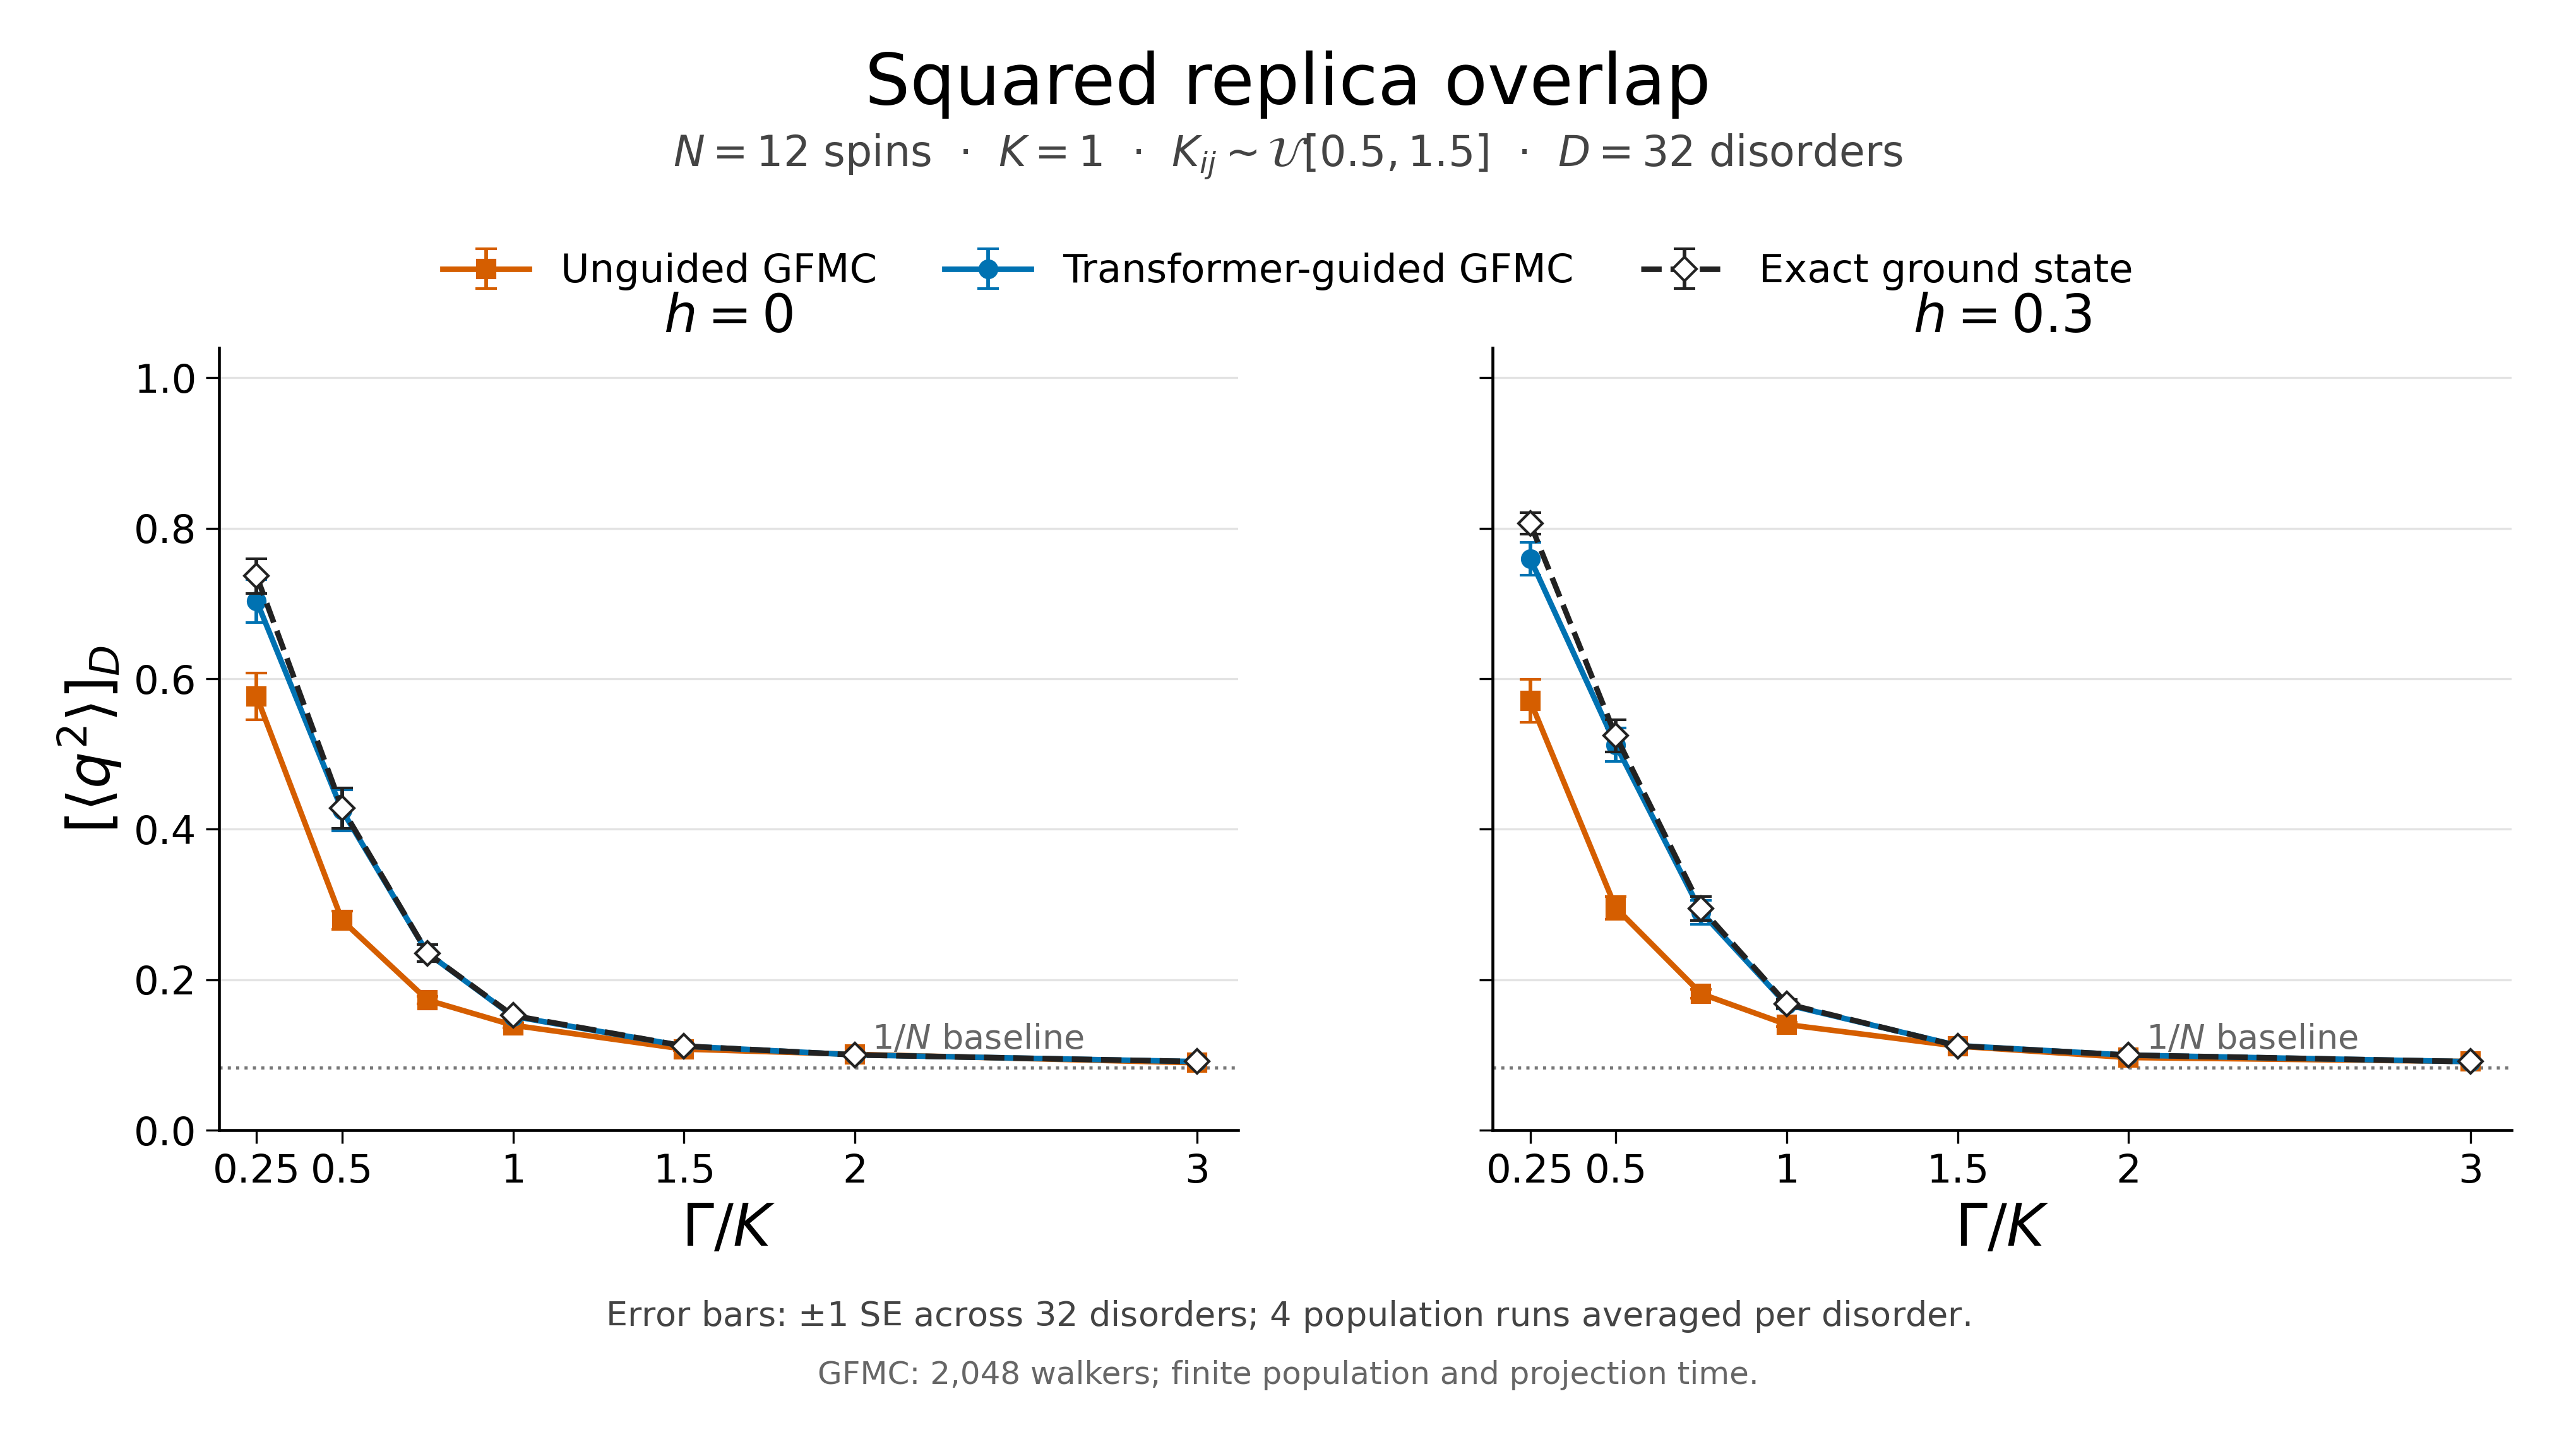

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

ROOT = Path('/Users/tianyiyan/Dropbox/spin-glasses')
RESULTS = ROOT / 'data/kagome/transformer_af_disorder_gfmc_v1'
manifest = json.loads((RESULTS / 'manifest.json').read_text())
audit = json.loads((RESULTS / 'audit.json').read_text())
assert audit['passed'] and audit['complete']
assert audit['checkpoint_sha256'] == manifest['checkpoint_sha256']
display(Markdown(
    f"**Completed baseline:** L={manifest['L']}, N={manifest['n_sites']}, "
    f"D={len(manifest['sample_ids'])}, R={len(manifest['seeds'])}; "
    f"{audit['populations']:,} population runs, {audit['caches']} exact/guide caches, "
    f"{audit['finite_forward']} finite-forward reference contexts. Final audit passed.\n\n"
    f"**Frozen checkpoint:** `{manifest['checkpoint_name']}`  \n"
    f"SHA-256: `{manifest['checkpoint_sha256']}`"
))
display(Image(filename=str(ROOT / 'figures/q2_vs_gamma.png'), width=1000))

## 1. What the completed study establishes

The 12-spin campaign covers $\Gamma/K=0.25,0.5,0.75,1,1.5,2,3$ and $h/K=0,0.3$, with 32 fresh disorders and four population repeats per point. It compares constant and frozen-transformer guides against exact ground states. The first eight disorders also have population, equilibration, forward-time and branching-cadence checks.

The guided $\langle q^2\rangle$ means closely follow the exact curve across much of the scan. The lowest-$\Gamma$ point retains a visible discrepancy. Larger populations gave the most consistent improvement; agreement in energy alone did not qualify the correlations. These findings motivate production work, but do not establish larger-size convergence.

At $h=0$, finite-size spin-flip symmetry forces our $q_{\mathrm{EA}}$ target to zero. The signed overlap estimator is sensitive to imperfect cancellation. Squared overlap is insensitive to independent global flips of the replicas; its improved agreement does not prove full sampling of the overlap distribution. Keep $q_{\mathrm{EA}}$ as a symmetry/sampling diagnostic.

The previous GFMC propagation used a complete lookup of the frozen network on the 12-spin Hilbert space. **That timing cannot be extrapolated to 48, 108, 192 or 300 spins.** Existing direct-inference pilots through $L=8$ establish that execution is possible; their short times and small populations do not qualify ground-state accuracy. New bounded $L=10$ probes are documented in the measured feasibility assessment below. They establish execution and short-run cost only; affordable, converged production still requires qualification. Reuse existing records for cost estimates only after checking their actual completion and configuration.

## 2. Fixed scientific specification

$$
H_J=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-\Gamma\sum_iX_i-h\sum_iZ_i,
\qquad K_{ij}\overset{\mathrm{iid}}{\sim}\mathcal U[0.5,1.5],\quad K=1.
$$

Use the kagome lattice with periodic boundaries and $N=3L^2$. Keep the bond width $w=0.5$ and use the full Cartesian product of these proposed production grids:

| Scan axis | Values in units $K=1$ | Number of values |
|---|---|---:|
| $\Gamma/K$ | $0.25,0.5,0.75,1,1.5,2,3$ | 7 |
| $h/K$ | $0,0.05,0.10,0.15,0.20,0.25,0.30$ | 7 |

This gives 49 field contexts per disorder, size, method, setting and independent repeat. The proposed $h$ spacing is $0.05$, preserving the original endpoints and adding five interior fields. Hold each bond realization fixed across both $\Gamma$ and $h$, methods, repeats and convergence settings. Identical sample IDs at different $L$ do not imply identical or nested bonds: the current disorder seed includes $L$.

Freeze the selected seed501 checkpoint recorded above. The main production claim concerns projection with this fixed guide. If retraining becomes necessary, make it a separate version, qualify it on development disorders, then freeze it before final evaluation. The earlier guide was trained at $L=2,4,6,8$; these sizes test performance on new disorders. The additions $L=5,7,9,10$ test unseen-size generalization and require separate guide and projector qualification.

| Role | Observable | Interpretation |
|---|---|---|
| Primary | $Q_2(J)=\langle q^2\rangle_J=N^{-2}\sum_{ij}\langle Z_iZ_j\rangle_J^2$ | Overlap magnitude and pair correlations |
| Primary companion at $h>0$ | $\chi_{\mathrm{conn},J}=N^{-1}\sum_{ij}\mathcal C_{ij}^2$ | Correlations beyond field-induced polarization |
| Numerical check | $E_J/N$ | Mixed energy estimator; assess alongside correlation convergence |
| Sampling check | $\langle q\rangle_J=N^{-1}\sum_i\langle Z_i\rangle_J^2$ | Zero at finite $N$, $h=0$, $\Gamma>0$ |
| Required scaling development | $\langle q^4\rangle$, connected overlap structure factors | Qualify dimensionless crossing diagnostics before final production |

Here $q=N^{-1}\sum_i Z_i^{(a)}Z_i^{(b)}$ and $\mathcal C_{ij}=\langle Z_iZ_j\rangle_J-\langle Z_i\rangle_J\langle Z_j\rangle_J$. All susceptibilities in this plan are equal-time quantities. The baseline $1/N$ is the diagonal contribution to $Q_2$ and its value for independent unbiased spins; it is not a phase boundary. At $h>0$, $Q_2$ also contains polarization contributions.

Report the equal-time overlap susceptibility $\chi_{\mathrm{SG}}^{\mathrm{eq}}=NQ_2$ alongside $\chi_{\mathrm{conn}}^{\mathrm{eq}}=N^{-1}\sum_{ij}\mathcal C_{ij}^2$, with their definitions attached to every map. Neither is automatically an imaginary-time-integrated response susceptibility. The finite-size $q_{\mathrm{EA}}=N^{-1}\sum_i\langle Z_i\rangle^2$ vanishes at $h=0$ for the unique finite-size symmetric ground state and contains field-induced polarization at $h>0$. Its map is a supporting observable; a thermodynamic glass-order claim requires a separately specified order of limits and symmetry-breaking protocol. Signed finite-sample estimates may fluctuate below zero and must retain their uncertainty.

Average per-disorder observables after forming replica moments. Use the existing four-replica forward-walking estimator for connected quantities, rather than squaring a noisy sample covariance. Retain every forward cycle and every disorder, including poor-ancestry cases.

## 3. Rollout and decision points

| Stage | Scope | Main question | Deliverable and gate |
|---|---|---|---|
| A — direct-path qualification | $L=2$, existing exact development benchmark | Does direct network inference reproduce the validated projector? | Exact-error, time/population and cache-invalidation checks pass |
| B — feasibility | $L=4$ ($N=48$), 4 development disorders, 3 $\Gamma$, 3 representative $h$ | Can direct GFMC support meaningful populations and projection times at an acceptable cost? | Measured throughput, memory, ancestry and a priced Stage C |
| C — convergence | $L=4$, 8 development disorders | Which parameters qualify $Q_2$ and connected correlations? | One-at-a-time escalation plus combined stress test meets prespecified tolerances |
| D — first production | $L=4$, 64 fresh disorders initially, full $7\times7$ field grid | Is the disorder average precise and stable? | Audited curves and maps with statistical and systematic uncertainty; extend to 128/256 if justified |
| E — size expansion | Full anchor surveys at $L=4,6,8,10$ under one protocol; add $L=5,7,9$ on matched transition cuts | Does the method remain feasible and converged as $N$ grows? | Repeat B/C and the common acceptance criteria for every size/context; qualify unseen sizes and cluster compatibility |
| F — primary inference | Target seven qualified sizes $L=4,5,6,7,8,9,10$, matched field cuts | Where is the transition, and how stable is its extrapolation? | Crossing drift, scaling fits and a phase-boundary estimate with statistical and systematic uncertainty, or a stated unresolved region |

Advance on evidence, rather than a fixed calendar. A stage can yield a smaller validated domain: for example, publish converged moderate/high-$\Gamma$ results while low-$\Gamma$ points remain visibly unresolved. Predeclare this convergence-based rule and retain those unresolved points in the coverage report.

**Current $L=10$ readiness:** the v1/v2/v3 benchmarks establish completed execution and short-run throughput measurements. Float32 remains a candidate inference mode; ensemble-level precision equivalence, longer-time/population convergence, qualified crossing observables and a measured production budget are pending. Record qualification and final-data status separately for every size/context under the common policy. Ready contexts can advance while others are being qualified.

Reserve compute for qualifying all seven target sizes and for transition-region refinement before expanding the $L=4$ disorder count beyond 64. Begin size-transfer and cost checks once the direct path is qualified; odd-size qualification need not wait for completion of the anchor maps. The target largest system is $10\times10$ kagome unit cells, $N=3\times10^2=300$, with PBC in both directions. Use the PBC $L=2$ exact study as a numerical anchor; test explicitly whether it belongs in any asymptotic fit. Four anchor sizes can locate a candidate transition, but offer limited support for simultaneous exponent and correction fits. Seven sizes allow stronger size-window and compatibility tests without guaranteeing asymptotic scaling. Budget limits can pause any size/context; pending anchor contexts remain part of the full survey scope.

### Shared production protocol

| Requirement | Common rule, including $L=10$ |
|---|---|
| Field coverage | All 49 $(\Gamma,h)$ combinations at each anchor size; matched prospective crossing refinements across participating sizes |
| Final sampling | Initially 64 fresh disorders and four independent population repeats per context; the same precision-driven extension policy |
| Guide comparison | Frozen guide throughout, plus the same preselected 16-disorder unguided subset and fixed-settings/equal-cost comparisons |
| Computations | Energy, $\langle q^2\rangle$, finite-size $q_{\mathrm{EA}}$, explicitly defined equal-time susceptibilities, qualified fourth moments, connected structure factors and conventional-order diagnostics |
| Qualification | The same development-selection policy, population/equilibration/forward-time/cadence ladders, alternative starts, ancestry checks and combined stress test |
| Acceptance and uncertainty | The common Section 7 tolerances, qualified crossing-error targets, disorder/run uncertainty analysis and fixed final-audit subset of at least eight disorders |
| Precision and provenance | The same validated inference-precision policy, double-precision projector arithmetic, frozen checkpoint/source identity, atomic outputs and coverage audit |

Equal standards do not imply identical converged walker counts or projection times. Select settings independently at each size/context using the same ladders and acceptance criteria, escalating when needed. No size receives looser tolerances or reduced estimator coverage to fit a runtime target. All anchor sizes retain the full grid in their completion accounting, even when common transition cuts are scheduled first.

## 4. Stage A: qualify the scalable implementation

Use eight of the existing 12-spin benchmark disorders as development cases and all 49 production field contexts. Reuse their existing exact references at $h=0,0.3$. Inventory compatible earlier references at the five interior fields; calculate the missing exact references and frozen-guide lookup tables before qualifying those contexts. At most $8\times7\times5=280$ additional exact/guide contexts are needed for this development subset. Store this extension in a new campaign directory with its own provenance.

1. Verify direct log amplitudes, all single-spin flip ratios, local energies and initialization probabilities against the frozen lookup for the same Hamiltonian. Exercise state-cache eviction and changes in $J$, $\Gamma$ and $h$. A cache must be scoped to the complete guide/context identity.
2. Compare constant-guide and direct-guide propagation on selected short cases. Use matched random streams where numerically practical; otherwise compare independent ensembles with uncertainty. Preserve four physical replicas per walker group and the same descendant weighting as the reference code.
3. Validate any throughput optimization at $L=2$ before applying it to larger-size production. For the measured float32 candidate, retain float64 as the comparison implementation, exact-check the small-system estimators, then compare independent float32/float64 ensembles on representative larger-size development contexts, including $L=10$. Assess $Q_2$, connected correlations and the chosen crossing observables alongside energy using prespecified precision-equivalence tolerances. Preserve double-precision rate/weight arithmetic. Batching and exact memoization may change cost; reduced precision, clipped rates or modified resampling can change numerical behavior and need explicit checks.
4. On the hardest development points, extend the current ladder to $W=8192,32768$, $\tau_{\mathrm{eq}}=32,64,128$, and $\tau_{\mathrm{FW}}=8,16,32$ as needed. Change one parameter at a time, starting from the existing results; then test the chosen settings jointly. Start with four independent runs, adding repeats when the convergence comparison is too noisy to resolve.

**Gate A:** direct-versus-lookup numerical checks pass, the completed original audit remains reproducible, and correlation errors against exact are quantified under the proposed ladder. Persistent low-$\Gamma$ error triggers further diagnosis; it does not invalidate already qualified points. If new code changes the algorithm, create a new source snapshot and repeat the relevant checks.

## 5. Stage B: a bounded 48-spin feasibility pilot

Use four development disorders, $\Gamma=0.5,1,2$, representative fields $h=0,0.15,0.3$, both guides, and four independent population runs. This initial configuration contains $4\times3\times3\times2\times4=288$ runs before escalations. Begin with $W=64$ four-replica walker groups, $\tau_{\mathrm{eq}}=2$, energy-measurement time $1$, $\tau_{\mathrm{FW}}=1$, four cycles and branch interval $0.1$. This is an execution/cost probe. Escalate representative contexts to $W=256$ and $1024$, plus longer projection, before extrapolating production cost. Benchmark $h=0$ separately because the symmetric guide requires extra network work; include $h=0.05$ in the escalation checks to probe the small nonzero-field regime.

Record elapsed time for initialization, direct network queries, propagation and reporting; GPU memory; unique/requested state queries; effective states/second; event counts; and ancestry versus forward time. Include both cold and warm cache behavior. Count $W$ as the number of four-replica groups, not the number of individual configurations.

Price the full algorithm, including guide inference and setup. Compare guided and unguided methods in two ways: identical populations/times to expose estimator behavior, and equal end-to-end compute to assess practical benefit. At $L=2$ use exact RMSE; at $L=4$ use precision and convergence evidence, explicitly acknowledging the absence of exact ground-state truth.

**Gate B:** the measured cost projects to a feasible Stage C within a recorded GPU-hour and memory budget, with room for repeats and failures. A production runner needs its own configuration, atomic outputs and budget cap; the existing hard-coded short-pilot runner is only a starting point. If $W\sim10^3$ and longer forward times are unaffordable, improve inference or projection before expanding disorders. A large count of short, collapsed runs cannot replace this gate.

**Implemented continuation (27 October 2026):** after all 288 base runs and their supervisor complete, a shared-lock controller dispatches 144 representative escalation runs on fixed development disorder 60000, at $\Gamma=0.5,2$ and $h=0,0.05$, with both guides, float64 and four independent repeats. This selection targets low-field ancestry and high-field cost without selecting by observable agreement. It is a bounded feasibility subset; Stage C still requires eight development disorders.

| Escalation | W | Equilibration | Forward time | Coverage |
|---|---:|---:|---:|---|
| Small-field baseline | 64 | 2 | 1 | h=0.05; reuse base pilot at h=0 |
| Population level 1 | 256 | 2 | 1 | All four selected field pairs |
| Population level 2 | 1024 | 2 | 1 | All four selected field pairs |
| Equilibration check | 1024 | 4 | 1 | All four selected field pairs |
| Forward-time check | 1024 | 2 | 2 | All four selected field pairs |

Measurement time 1, four cycles and branch interval 0.1 are fixed throughout. Population comparisons and each time comparison change exactly one parameter. Independent seeds are checked across both queues. The controller preserves the original 17:46:47 UTC deadline, checkpoints at expiry and never automatically admits Stage C or final data.

`assess_stage_b.py` exports context coverage, independent-run/disorder uncertainty, all cycle-level ancestry and a provisional Stage C cost worksheet. W64-based linear cost extrapolation is an explicit scenario until checked against W256/W1024 and longer-time measurements. Equal-cost guide comparisons, event counts and separate cold/warm-cache and timing-component profiles remain required Gate B work; the current records do not provide all these diagnostics.

## 6. Stage C: qualify populations, projection and ancestry at 48 spins

Use eight development disorders: four fixed in advance and four added by a documented difficult-case rule based on runtime/ancestry, not agreement with a desired curve. Start at $\Gamma=0.5,1,2$ and $h=0,0.15,0.3$. Include $\Gamma=0.25$ and $h=0.05$ as stress cases before admitting them to the qualified scan. Extend the convergence comparisons to the remaining $\Gamma=0.75,1.5,3$ and $h=0.10,0.20,0.25$ before applying a setting policy to their combinations. All 49 contexts require recorded qualification evidence; apparent smoothness in $h$ does not establish convergence.

| Parameter | Candidate ladder | What it diagnoses |
|---|---|---|
| Walker groups $W$ | $512,2048,8192$; extend only if feasible | Population bias and loss of independent lineages |
| Equilibration $\tau_{\mathrm{eq}}$ | $16,32,64$ | Initial-state dependence and incomplete projection |
| Forward time $\tau_{\mathrm{FW}}$ | $4,8,16$ | Residual trial-state dependence of replica observables |
| Branch interval $\Delta\tau$ | $0.1,0.05$; add $0.025$ when needed | Finite-population sensitivity to resampling cadence |
| Forward cycles / repeats | $16,32$ cycles; $R=4$, then $8$ if needed | Statistical precision; cycles may be correlated |

These are candidate brackets, not certified values transferred from 12 spins. Start from the strongest feasible configuration suggested by B. Escalate each parameter separately, then combine the chosen larger population and longer times to detect interactions. Add checkpoints along a run where practical, preserving the same target definition.

Inspect mixed/growth energies, $Q_2$, $\chi_{\mathrm{conn}}/N$, overlap signs and initial-state dependence. Use guide-initialized runs and independent alternative initial states, with their initialization protocol recorded. At $h=0$, monitor the overlap distribution and spin-flip symmetry even if $Q_2$ looks stable. A symmetry-restoring move is a possible later algorithm change, requiring separate qualification.

Report descendant ESS, unique ancestors and largest-lineage fraction for **each** forward cycle and their distributions over disorders. As an initial alarm, any cycle with descendant ESS below 8 or a lineage fraction above 0.5 triggers review and a stronger run; these are failure alarms, not accuracy certificates. Never drop an unfavorable cycle to improve agreement. If longer forward time improves bias but collapses ancestry, increase population or change the separately validated algorithm.

## 7. Quantitative qualification and precision targets

Set the tolerances before evaluating the final disorders. The following are provisional absolute tolerances, in units $K=1$:

| Observable | Desired final disorder-average SE | Maximum unresolved numerical shift |
|---|---:|---:|
| $Q_2$ | $0.005$ | $0.002$ |
| $\chi_{\mathrm{conn}}/N$ | $0.005$ | $0.002$ |
| $E/N$ | $0.002$ | $0.001$ |

For each escalation form per-disorder differences between the stronger and candidate settings, averaging independent repeats within each disorder. Estimate the uncertainty of the mean difference using paired disorder resampling and independent-run variation. Pairing refers to the same Hamiltonian; random seeds do not make two different algorithms' trajectories identical.

An operational equivalence gate for observable $O$ is

$$
|\overline{\Delta O}|+1.96\,\operatorname{SE}(\overline{\Delta O})\leq\epsilon_O.
$$

Use this as a prespecified approximate 95% criterion, checking bootstrap intervals and repeat stability when the distribution is skewed. Require it for the final two relevant population/time levels and the combined stress test, at each qualified field context. If only two levels have been measured, add a third before claiming a plateau. If the interval is too wide, gather more repeats; an insignificant difference is not an equivalence result. Tolerance changes require a new documented target, never a silent relaxation after seeing results.

Check per-disorder absolute shifts and tails as well as their signed average, so opposite biases cannot cancel unnoticed. Broad confidence intervals from eight pilot disorders can require a larger qualification subset. At $L=2$, also compare directly to exact truth. At larger sizes this procedure establishes empirical stability over the tested range, not a rigorous upper bound on ground-state bias.

On the final sample, preselect at least eight audit disorders and repeat the stronger settings; expand that subset when numerical tails appear. Stronger runs on flagged disorders supplement this fixed subset. Report a separate systematic-sensitivity envelope, aiming for numerical uncertainty below half the achieved statistical SE. Tightening the statistical SE later can therefore require stronger numerical qualification.

## 8. Stage D: a fresh disorder average and defensible error bars

Once C passes, freeze the setting policy, source tree and checkpoint. Allocate a new development pool and final pool in a manifest after checking existing IDs. A suggested candidate allocation is IDs `60000:60032` for development and `61000:61256` for up to 256 final disorders; these ranges require a repository-wide collision/training-split check before reservation. Existing IDs `40000:40008` were reserved for another purpose and remain reserved.

Begin with the first 64 final disorders at $L=4$, four independent runs per point, all 49 combinations of the seven $\Gamma$ and seven $h$ values, and the qualified settings. Prioritize completing all matched contexts for a disorder. Add disorders in prespecified blocks of 64, up to 256, if the target precision is unmet. This is a sequential precision policy; report each checkpoint and the stopping rule. Treat ordinary pointwise SE/intervals as descriptive under that stopping policy unless a sequentially valid procedure is implemented.

For the main large-system campaign, run the guided method throughout. Retain both guides across the full $7\times7$ grid on a fixed 16-disorder subset of the final pool for matched and equal-cost comparisons. Enlarge the baseline subset if the comparison is inconclusive. The code cell below also prices a full two-method design. Fix the subset before reading its results. Changes to either field grid based on a pilot must be frozen before collecting the final pool; a later denser scan becomes a separately declared extension.

Apply the full survey design identically to $L=4,6,8,10$, with 49 contexts, initially 64 fresh disorders, four repeats and the same 16-disorder unguided comparison policy at each size. At $L=5,7,9$, retain the planned common selected transition cuts under the same per-context computations and numerical standards. Specify the unique $(\Gamma,h)$ contexts in a manifest so intersecting cuts are counted once. Choose cuts from development evidence, then freeze them before final confirmation; compare sizes at the same field values.

Generate an independent propagation RNG for each $(L,J,\Gamma,h,\mathrm{method},\mathrm{setting},r)$ using a stable, stored seed mapping. Keep disorder generation separate. The old campaign reused seed labels across contexts; its disorder bars condition on those streams. Fresh independent streams simplify the next campaign's uncertainty accounting.

For independent disorder and run streams,

$$
\widehat O_J=\frac1R\sum_{r=1}^{R}\widehat O_{J,r},\qquad
\overline O=\frac1D\sum_{J=1}^{D}\widehat O_J,\qquad
\widehat{\operatorname{SE}}(\overline O)=\frac{\operatorname{sd}_J(\widehat O_J)}{\sqrt D}.
$$

The last expression includes finite-run Monte Carlo scatter. Show a separate estimate of that contribution,

$$
\widehat{\operatorname{Var}}_{\mathrm{MC}}(\overline O)
=\frac{1}{D^2}\sum_{J=1}^{D}\frac{s_J^2}{R},
$$

where $s_J^2$ is the sample variance across the independent run means. Do not add this again to the disorder-level variance above. If estimating the intrinsic disorder variance, subtract the average within-disorder Monte Carlo variance with explicit finite-sample uncertainty. If MC dominates, buy more independent repeats or longer validated measurements; if disorder scatter dominates, buy more disorders.

Use paired disorder bootstrap intervals for method differences and derived ratios, retaining the entire $(\Gamma,h)$ grid for a disorder together. Label intervals as pointwise; claims across the full map require simultaneous uncertainty assessment. Use independent run-level variance to assess MC contamination, avoiding naive nested resampling that counts it twice. Inspect distributions and leave-one-disorder-out sensitivity. Retain rare disorders at equal weight; rerun difficult cases to reduce uncertainty without selecting by observable value.

## 9. Workload and budget worksheet

The following counts cover the full $7\times7$ grid and are a planning envelope for one production setting per point. They exclude development ladders and the stronger final-sample audit. Compared with the original two-field design, there are $7/2=3.5$ times as many production runs at each disorder count. This is a run-count multiplier; the GPU-hour multiplier depends on measured field-specific timings. A population run contains four physical replicas per walker group. Any field context awaiting qualification remains a proposed run, not a certified result.

Use the feasibility pilot to measure end-to-end seconds per run separately by size, field, $\Gamma$ and method. For a serial GPU schedule,

$$
T_{\mathrm{GPU\ hours}}\approx\frac{1}{3600}\sum_{c\in\mathrm{contexts}}n_c\,t_c.
$$

Include guide loading/setup, convergence ladders, the final audit and retries. Initially reserve 30% contingency on top of measured estimates and display the underlying timing quantiles. If jobs share a GPU, measure aggregate throughput under that exact concurrency; summing overlapped wall times is not device-hours. The relative pilot cost is more useful than a calendar promise at this stage.

In [2]:
# Explicit proposed production grids; the manifest above describes the completed baseline.
gammas = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
fields = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
repeats = 4
baseline_disorders = 16
display(Markdown(
    f'**Proposed production grid:** {len(gammas)} Gamma values × '
    f'{len(fields)} h values = {len(gammas)*len(fields)} contexts per disorder.  \n'
    f'Gamma/K: `{gammas}`  \n'
    f'h/K: `{fields}`'
))
lines = [
    '| Final disorders per size | Guided runs | Extra unguided runs (16 disorders) | Recommended total | Full two-method total |',
    '|---:|---:|---:|---:|---:|'
]
for disorders in (64, 128, 256):
    guided = disorders * len(gammas) * len(fields) * repeats
    baseline = baseline_disorders * len(gammas) * len(fields) * repeats
    lines.append(f'| {disorders} | {guided:,} | {baseline:,} | {guided+baseline:,} | {2*guided:,} |')
display(Markdown('\n'.join(lines)))
anchor_sizes = [4, 6, 8, 10]
additional_cut_sizes = [5, 7, 9]
scaling_sizes = sorted(anchor_sizes + additional_cut_sizes)
initial_per_size = (64 + baseline_disorders) * len(gammas) * len(fields) * repeats
anchor_total = len(anchor_sizes) * initial_per_size
display(Markdown(
    f'**Anchor-map envelope:** {len(anchor_sizes)} sizes '
    f'(L = {anchor_sizes}) × {initial_per_size:,} runs/size '
    f'= {anchor_total:,} runs. '
    'All four anchor sizes share the full survey design and qualification standards; '
    'qualification, audit and transition-region refinement are additional.'
))
per_context = (64 + baseline_disorders) * repeats
cut_rows = [
    '| Unique field contexts C on common cuts | Seven-size cut campaign alone | Extra L=5,7,9 runs | Anchor maps + extra sizes, if cuts lie on survey grid |',
    '|---:|---:|---:|---:|'
]
for contexts in (7, 14, 21):
    added = len(additional_cut_sizes) * per_context * contexts
    cut_rows.append(
        f'| {contexts} | {len(scaling_sizes)*per_context*contexts:,} | '
        f'{added:,} | {anchor_total+added:,} |'
    )
display(Markdown('\n'.join(cut_rows)))
display(Markdown(
    '**Illustrative counts:** C is the number of unique field pairs, not the number of cuts. '
    'For shared cuts containing C_off new points outside the survey grid, add '
    f'{len(anchor_sizes)*per_context:,} × C_off anchor-size runs to the last column. '
    'Count every size/context once; qualification, stronger audits and extra precision runs are additional.'
))

size_rows = ['| L | N | Uncorrelated baseline 1/N | Status in this plan |',
             '|---:|---:|---:|---|']
for L in [2] + scaling_sizes:
    sites = 3*L*L
    status = 'Completed exact benchmark' if L == 2 else (
        'Full 49-context survey and matched cuts; common production protocol' if L in anchor_sizes
        else 'Transition cuts; common numerical standards and compatibility checks')
    size_rows.append(f'| {L} | {sites} | {1/sites:.6f} | {status} |')
display(Markdown('\n'.join(size_rows)))

# Fill from the Stage B/C timing records before scheduling production.
# Keys should identify L, h, Gamma and method; values are end-to-end seconds/run.
measured_seconds_per_run = {}
display(Markdown('**GPU-hour estimate pending:** larger-system production timings have not been inserted.'))

**Proposed production grid:** 7 Gamma values × 7 h values = 49 contexts per disorder.  
Gamma/K: `[0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]`  
h/K: `[0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]`

| Final disorders per size | Guided runs | Extra unguided runs (16 disorders) | Recommended total | Full two-method total |
|---:|---:|---:|---:|---:|
| 64 | 12,544 | 3,136 | 15,680 | 25,088 |
| 128 | 25,088 | 3,136 | 28,224 | 50,176 |
| 256 | 50,176 | 3,136 | 53,312 | 100,352 |

**Anchor-map envelope:** 4 sizes (L = [4, 6, 8, 10]) × 15,680 runs/size = 62,720 runs. All four anchor sizes share the full survey design and qualification standards; qualification, audit and transition-region refinement are additional.

| Unique field contexts C on common cuts | Seven-size cut campaign alone | Extra L=5,7,9 runs | Anchor maps + extra sizes, if cuts lie on survey grid |
|---:|---:|---:|---:|
| 7 | 15,680 | 6,720 | 69,440 |
| 14 | 31,360 | 13,440 | 76,160 |
| 21 | 47,040 | 20,160 | 82,880 |

**Illustrative counts:** C is the number of unique field pairs, not the number of cuts. For shared cuts containing C_off new points outside the survey grid, add 1,280 × C_off anchor-size runs to the last column. Count every size/context once; qualification, stronger audits and extra precision runs are additional.

| L | N | Uncorrelated baseline 1/N | Status in this plan |
|---:|---:|---:|---|
| 2 | 12 | 0.083333 | Completed exact benchmark |
| 4 | 48 | 0.020833 | Full 49-context survey and matched cuts; common production protocol |
| 5 | 75 | 0.013333 | Transition cuts; common numerical standards and compatibility checks |
| 6 | 108 | 0.009259 | Full 49-context survey and matched cuts; common production protocol |
| 7 | 147 | 0.006803 | Transition cuts; common numerical standards and compatibility checks |
| 8 | 192 | 0.005208 | Full 49-context survey and matched cuts; common production protocol |
| 9 | 243 | 0.004115 | Transition cuts; common numerical standards and compatibility checks |
| 10 | 300 | 0.003333 | Full 49-context survey and matched cuts; common production protocol |

**GPU-hour estimate pending:** larger-system production timings have not been inserted.

## 10. Stage E/F: size expansion and physical conclusions

Develop the anchor sizes $L=4,6,8,10$ alongside the additional cut sizes $L=5,7,9$, repeating the cost and convergence gates at each size. Keep the same disorder distribution and PBC, with common field points on each scaling cut. New sizes may require more walkers, longer times or a different validated projector; do not carry settings over solely because the energy looks reasonable. If the frozen guide becomes too costly or inaccurate, finish the validated size/domain and develop a separately versioned improvement.

### Seven-size design and cluster compatibility

Four sizes provide useful exploratory crossings but only limited tests of finite-size corrections. Neighboring-size crossings share measurements and are correlated; six adjacent-size crossings from seven sizes are also not six independent estimates. The primary target is a stable critical-field estimate. Report critical exponents only if size-window and fit-form tests support them; do not simultaneously fit a flexible scaling function and unconstrained correction exponents merely because seven sizes are available.

Before pooling sizes, verify site/bond counts, periodic connectivity, allowed reciprocal momenta and consistent physical lattice geometry. Check whether candidate conventional ordering wavevectors fit each periodic cluster. Compare odd/even sequences and other relevant commensurability classes, using disorder-averaged structure factors and scaling residuals. Random bonds do not automatically remove finite-cluster compatibility effects. Set the admission/analysis rules using development data and physical geometry, then freeze them before final confirmation. If sequences differ, analyze compatible families or a justified correction model; preserve and report every size rather than dropping inconvenient results after seeing the boundary.

The additions $L=5,7,9$ require frozen-guide construction, ratio/cache and observable checks as well as the usual convergence ladders. Successful even-size inference does not qualify odd sizes. Use alternative initial states and independent runs to diagnose slow-mode or cluster effects near the crossing region.

Start with common cuts suggested by the anchor survey, add the three intermediate sizes at those field values, and refine the crossing brackets across all admitted sizes. Test increasing minimum size, leave-one-size-out fits, compatible-family fits, and the influence of $L=10$. Report how the inferred critical field and any exponent move under each test. If only one compatibility family has enough useful sizes, report that effective size count. More points within $4\leq L\leq10$ improve these tests but do not extend the maximum length: persistent drift among the largest sizes may require systems beyond $L=10$ or an unresolved extrapolation.

### Applying the common protocol at $10\times10$ PBC

$L=10$ has the same full production scope and acceptance standards as the other anchor sizes. The bounded execution benchmarks are complete and should be reused as evidence; the work below applies the shared protocol at 300 spins. Preserve their source snapshots and records. These are size-specific checks within the common qualification process.

1. **Check unseen-size construction and estimator arithmetic.** Verify 300 sites, periodic nearest-neighbor connectivity and the intended disorder reconstruction. Load the frozen checkpoint without changing parameter shapes; check finite log probabilities, samples, all-spin flip ratios, context changes and cache eviction. Compare selected flip ratios with direct log-amplitude differences. Check integer accumulation and overlap/moment normalization at 300 spins; an overflow or a sequence-length assumption can invalidate a large-size run even when the model loads.
2. **Measure H800 feasibility early.** Start with four development disorders at $\Gamma=0.5,1,2$ and $h=0,0.15,0.3$, using bounded short jobs and the Stage B protocol. Benchmark inference chunk sizes and worker concurrency anew at $L=10$. Measure initialization, all-flip query cost, complete event propagation, GPU/RAM peaks and ancestry. Escalate feasible populations and projection times before estimating production cost. Memory fit alone is insufficient; local proposals require many network evaluations and long-time convergence may dominate cost.
3. **Qualify the same ground-state observables.** Apply the Stage C development-selection policy and the common population, equilibration, forward-time and cadence ladders to all 49 contexts, plus prospective crossing refinements. Verify fourth moments and connected structure factors, alternative starts and independent repeats. The new size lies outside the guide's training sizes, so quantify guide quality and efficiency on development cases; neither successful inference nor smooth energy establishes correlation convergence. Apply the same Section 7 tolerances and crossing-error criteria used for the other sizes.
4. **Complete the same final-data design.** Use the separately reserved fresh pool, initially 64 disorders and four independent repeats at every one of the 49 field contexts, with the same 16-disorder unguided comparison policy and stronger audit on at least eight preselected disorders. Extend by the shared precision rule. Schedule matched transition brackets first across $L=4,5,6,7,8,9,10$ while retaining the full anchor grids as required coverage. A budget-limited pause leaves outstanding contexts pending; it does not redefine $L=10$ as a cut-only or completed case.
5. **Promote qualified contexts explicitly.** Include $L=10$ in boundary fits only after its numerical sensitivity is below the crossing-error budget. Compare fits with and without the smaller sizes and with and without $L=10$. If a context fails qualification, retain it in the pipeline as unresolved and use the qualified size/domain while optimizing or separately retraining the guide. Seven target sizes still require restrained fit complexity and checks of scaling assumptions.

The worksheet prices four anchor maps and selected cuts at the three added sizes. For $C$ unique field contexts at one size, the initial 64-disorder guided campaign plus the 16-disorder unguided comparison costs $(64+16)\times4\times C=320C$ runs. Seven-size cuts alone cost $2240C$ runs; adding $L=5,7,9$ to matching existing anchor data costs $960C$ runs. New refined field points also require anchor-size runs, at $1280$ per new common field pair. These counts exclude qualification, stronger audits and extra precision runs. Measure seconds/run at each size before converting counts into GPU-hours.

Plot $[Q_2]_D$, finite-size $[q_{\mathrm{EA}}]_D$, $[\chi_{\mathrm{SG}}^{\mathrm{eq}}]_D$ and $[\chi_{\mathrm{conn}}^{\mathrm{eq}}]_D$ against $\Gamma$ at each of the seven $h$ values, and against $h$ at each of the seven $\Gamma$ values, for each qualified size. Add maps over $(\Gamma,h)$ with unresolved contexts visibly marked, and show each size's $1/N$ reference for $Q_2$ where useful. Add uncertainty on changes with size. The $7\times7$ grid is a survey; any proposed transition region needs a prospectively declared denser grid and convergence checks there.

At $h=0$, a candidate dimensionless crossing diagnostic to qualify before production is

$$
g_L=\frac12\left(3-\frac{[\langle q^4\rangle]_D}{[\langle q^2\rangle]_D^2}\right).
$$

This is a ratio of disorder-averaged moments, not an average of per-disorder ratios. Record the convention and obtain its uncertainty by paired disorder resampling. Qualify fourth moments independently: they may require more samples than $Q_2$. Connected structure-factor ratios provide another candidate, after momentum and lattice conventions are checked. At nonzero field use a separately defined connected diagnostic; the uncentered Binder ratio includes polarization.

Finite-size crossings or a large $Q_2$ alone do not establish a spin-glass phase. Examine drift, finite-size corrections and possible conventional magnetic order using appropriate spin structure factors before making a glass interpretation. A thermodynamic $q_{\mathrm{EA}}$ claim also needs a stated symmetry-breaking/order-of-limits protocol, beyond the finite-size signed-overlap estimator used here.

### Phase-boundary inference protocol

1. **Define the crossing observables first.** Qualify the Binder convention above at $h=0$ and a connected overlap structure-factor ratio at finite field. One candidate is $R_L=1-S_{\mathrm{conn}}(\mathbf k_{\min})/S_{\mathrm{conn}}(0)$, where $S_{\mathrm{conn}}(\mathbf k)=N^{-1}\sum_{ij}\mathcal C_{ij}^2\exp[i\mathbf k\cdot(\mathbf r_i-\mathbf r_j)]$. Specify kagome basis positions, reciprocal primitive vectors and equivalent minimum-momentum directions; validate translation, reality, normalization and the four-replica estimator against exact results. Do not import a square-lattice correlation-length formula without deriving its geometry factors. Check the theoretical scaling of the equal-time quantity at this quantum transition before assuming a dimensionless ratio has size-independent crossings; a time-integrated diagnostic may require additional estimator development.
2. **Survey common cuts across sizes.** Use fixed-$h$ cuts in $\Gamma$ and fixed-$\Gamma$ cuts in $h$ on the shared PBC grid. Inspect candidate crossing intervals, conventional magnetic order and distribution tails. A smooth map or a finite-size susceptibility peak alone does not locate a critical point. Allow for no transition in the scanned domain, first-order behavior, or a crossover.
3. **Refine crossing brackets prospectively.** Add common field values for every participating size where the coarse scan suggests crossings. Choose spacing so interpolation uncertainty is smaller than the target critical-field uncertainty, and check it with an additional refinement. Freeze the refinement rule and use fresh confirmation disorders to assess choices made using development data. Agree on the desired uncertainty in $\Gamma_c(h)$ or $h_c(\Gamma)$ after pilot slopes and costs are available; the observable tolerance $0.002$ alone is not a critical-field error budget.
4. **Fit crossing drift and size dependence.** If a continuous transition and the chosen scaling form are supported, examine $R_L(t)=F(tL^{1/\nu})+L^{-\omega}G(tL^{1/\nu})$, with $t=\Gamma-\Gamma_c(h)$ or $h-h_c(\Gamma)$. Use the linear extent $L$, not $N=3L^2$, as the scaling length. Avoid unconstrained multi-parameter fits to only a few sizes. Vary the smallest included size, field window, correction terms and interpolation method, and compare multiple independently motivated diagnostics. Report instability when these choices move the inferred boundary substantially.
5. **Propagate covariance through the full inference.** Resample each disorder's entire field grid and moment set together, recomputing ratios, interpolation, crossings and fits in each replicate. Current disorder generation gives independent samples across sizes, so bootstrap each size independently; pairing numerical sample IDs across $L$ would impose false covariance. Account for independent-run MC uncertainty without counting it twice. Report pointwise boundary intervals and any simultaneous band distinctly, plus numerical-convergence and fit-choice sensitivity.
6. **Requalify near the candidate transition.** Increase projection/equilibration times and populations as size grows; slow modes and reduced gaps can require more stringent settings precisely where the boundary is inferred. Confirm that numerical shifts in the inferred crossing are below its declared error budget. Ancestry, alternative initial states, fourth moments and connected estimators all need checks at the refined points. Ground-state projection times must be converged separately at every size; fixed times do not establish the zero-temperature limit.

The release target is a table of candidate critical fields versus $h$ (or versus $\Gamma$), the sizes and observables used, crossing brackets, uncertainty components and fit stability. Include unresolved regions explicitly. The two-dimensional observable maps accompany this table and the underlying finite-size curves.

### Ancestry-onset hypothesis, exact P(q), and targeted refinement

**User-directed investigation:** retain the small-$\Gamma$ regime as a physics target. Test whether the onset of ancestry loss marks a difficult physical region by comparing it with exact small-system overlap distributions, then refine common field cuts around candidate physical crossings and attempt finite-size extrapolation. The suggestion that ancestry onset coincides with a phase transition is a hypothesis; sampler collapse also depends on the guide and numerical parameters.

For each disorder define the equal-time two-copy distribution
$P_J(q)=\sum_{s,t}|\psi_J(s)|^2|\psi_J(t)|^2\,\mathbf1[q=N^{-1}\sum_i s_i t_i]$.
Average distributions over equally weighted disorders. At $h=0$, keep the full signed distribution and verify spin-flip symmetry; at nonzero $h$, report polarization and connected diagnostics alongside $P(q)$. Small exact clusters show crossovers rather than thermodynamic singularities.

1. **Completed exact-distribution implementation:** `assess_overlap_onset.py` reuses 392 existing $L=2$, 12-spin exact ground states across eight disorders and 49 fields. It computes the full $P_J(q)$ using XOR convolution, checks its first/second/fourth moments against existing references and compares it with the frozen guide's unprojected $P_J(q)$. It exports CSV, PNG/PDF and Markdown with input hashes. This requires no new diagonalization.
2. **Onset scan after current escalation review:** at $h=0,0.05$, propose common $\Gamma=2,1.75,1.5,1.25,1,0.75,0.5$, four fixed development disorders, four independent repeats and $W=256,1024$. Hold equilibration2/measurement1/forward1/cycles4/branch0.1 fixed. Compare alarm fraction, ESS/W and lineage distributions. A diagnostic half-alarm crossing is reported only if measured points bracket it; inspect nonmonotonicity and dependence on $W$, projection time and guide. These are proposed development tasks, not automatically dispatched or qualified final data.
3. **Local interpolation and confirmation:** use the onset bracket to prioritize a physical-observable survey. At each fixed $h$, refine actual Binder/connected-ratio crossing brackets by common midpoint fields across all admitted sizes. Interpolate only within measured brackets; preserve multiple crossings and report missing ones. Refine again until field interpolation error is subdominant. Use fresh confirmation disorders after selecting brackets with development data.
4. **Finite-size extrapolation:** first inspect qualified even-size curves $L=4,6,8,10$, then compatible odd-size cuts $L=5,7,9$. Use $L$ as length. Exclude $L=2$ from the primary thermodynamic fit because of its short extent and potential large corrections, but show it as an exact benchmark. Fit candidate crossing drift $\Gamma_\times(L_1,L_2)=\Gamma_c+A\ell^{-\lambda}$ with $\ell=\sqrt{L_1L_2}$ as an explicitly phenomenological convention. Prefer fixed-ratio compatible pairs where coverage permits. Vary fixed positive $\lambda$ (initial sensitivity values 1,2,3), minimum size and pair family; do not infer an unconstrained correction exponent from sparse crossings. Do not interpret this drift convention as a derived universal law.
5. **Covariance and scaling:** resample each disorder's entire field curve and moment set together, bootstrap different sizes independently, recompute all shared-size crossings jointly and propagate their covariance through drift fits. Test $R_L=F((\Gamma-\Gamma_c)L^{1/\nu})+\cdots$ only if a continuous transition and the equal-time ratio's scaling are supported. The current narrow size range may not constrain $\nu$ or $\Gamma_c$ reliably; test alternative behavior and conventional order. Compare drift models and report numerical, statistical, interpolation and size-window sensitivity separately.
6. **Executable support and present limit:** `finite_size_crossings.py` implements bracketed crossings and conditional drift fits from joint bootstrap samples; independent synthetic tests check interpolation and recovery. Present data contain exact $N=12$ references and unqualified $N=48$ development runs. They do not yet support a measured physical crossing, a thermodynamic extrapolation or an exponent estimate. Record these as pending rather than fitting ancestry alarms as an order parameter.

The active base pilot and its bounded population/time escalations continue. Additional field and size tasks follow measured feasibility and numerical qualification. Full anchor-grid scope and common acceptance criteria remain unchanged.

## Measured L=10 feasibility evidence

The assessment below is generated from saved H800 measurements, with immutable source snapshots and checkpoint identity. Its cost scenarios are deliberately conditional. The full survey run counts in Section 9 remain scope calculations, not a funded or throughput-qualified schedule. Direct-inference optimization and validation must pass before dispatching the proposed large population/time ladders.

**Measured decision:** 300-spin PBC construction, checkpoint loading and short four-replica GFMC run successfully on the current H800. Inference is the dominant cost. At $\Gamma=0.5$ on one disorder, 32 walker groups evolved for total imaginary time $0.2$ in about 85 s ($h=0.3$) or 164 s ($h=0$) using float64. A separate float32-inference probe took about 4.2 s and 8.2 s, respectively, with small sampled rate differences but no long-run accuracy qualification. Preserve float64 as the comparison path; prioritize precision validation and measured throughput improvements before larger production allocations. Even a 20-fold speedup does not by itself price the full campaign: the old 12-spin population/time settings remain expensive under a simple extrapolation and have not been qualified at $L=10$.

In [3]:
assessment = ROOT / 'data/kagome/transformer_af_l10_feasibility_v1/ASSESSMENT.md'
if assessment.exists():
    display(Markdown(assessment.read_text()))
else:
    display(Markdown('Measured assessment not present locally; regenerate it from the saved feasibility records.'))

# L=10 (300-spin PBC kagome) measured feasibility

## Scope and status

Bounded AutoDL H800 probes using the frozen seed501 checkpoint, one disorder (ID 10000), Gamma=0.5, and h=0 or 0.3. These are execution and cost measurements, not converged ground-state or phase-boundary results. Probe source snapshots are retained and their recorded hashes verified by this report generator.

- v1: **completed**, 127.1 s; 2026-10-27T05:11:39Z; precision: float64.
- v2: **completed**, 319.2 s; 2026-10-27T05:14:53Z; precision: float64.
- v3: **completed**, 47.1 s; 2026-10-27T05:20:49Z; precision: float64 versus float32.

## Current float64 inference

| L | Spins | h | Configurations | All-flip seconds | Peak allocated GiB |
|---:|---:|---:|---:|---:|---:|
| 8 | 192 | 0.3 | 128 | 1.731 | 0.924 |
| 8 | 192 | 0.0 | 128 | 3.461 | 0.927 |
| 10 | 300 | 0.3 | 128 | 5.477 | 1.925 |
| 10 | 300 | 0.0 | 128 | 10.960 | 1.930 |

All-flip queries evaluate the ratios needed to choose a single-spin event. The current projector repeatedly requests these ratios during propagation; its exact state cache avoids repeated queries when states recur. Peak allocated memory is PyTorch allocation, not total device memory or a production memory estimate.
The v1 128-configuration float64 L=10 batches allocate about 1.93 GiB. The longer v2 probe also completed with 128 four-replica groups (512 configurations), using about 2.18 GiB peak allocated memory. Production populations and cache storage need their own memory measurements.

## End-to-end short projection

| Probe | L | h | Inference | Four-replica walker groups | Total imaginary time | Wall seconds | Inference seconds | Minimum descendant ESS |
|---|---:|---:|---|---:|---:|---:|---:|---:|
| v1 | 10 | 0.3 | float64 | 8 | 0.025 | 4.735 | 4.187 | 8.00 |
| v1 | 10 | 0.0 | float64 | 8 | 0.025 | 9.279 | 8.733 | 8.00 |
| v1 | 8 | 0.3 | float64 | 8 | 0.025 | 1.149 | 0.930 | 8.00 |
| v1 | 10 | 0.3 | float64 | 32 | 0.025 | 16.851 | 15.127 | 30.12 |
| v2 | 10 | 0.3 | float64 | 32 | 0.200 | 84.875 | 82.849 | 21.33 |
| v2 | 10 | 0.0 | float64 | 32 | 0.200 | 163.647 | 161.856 | 25.60 |
| v2 | 10 | 0.3 | float64 | 128 | 0.025 | 68.358 | 61.566 | 122.27 |
| v3 | 10 | 0.3 | float32 | 32 | 0.200 | 4.238 | 4.008 | 22.26 |
| v3 | 10 | 0.0 | float32 | 32 | 0.200 | 8.159 | 7.929 | 21.33 |

Healthy ancestry over these very short forward times does not predict ancestry at production forward times. Each projector context has one seed; no disorder average or confidence interval on accuracy is inferred.

## Float32 speed/error probe (candidate only)

The precision probe uses full float32 matmul (highest setting), 128 guide-drawn and 32 independent random configurations. Errors compare the same configurations against float64. The projector adapter retains double-precision NumPy rate/weight arithmetic. Changing inference precision is not yet qualified for production.

| h | Chunk | Float64 seconds | Float32 seconds | Speed ratio | Max relative rate error | Max local-energy/site error |
|---:|---:|---:|---:|---:|---:|---:|
| 0.3 | 512 | 6.834 | 0.338 | 20.2x | 3.24e-05 | 2.04e-05 |
| 0.3 | 2048 | 6.834 | 0.320 | 21.4x | 3.24e-05 | 2.04e-05 |
| 0.0 | 512 | 13.664 | 0.678 | 20.1x | 3.82e-05 | 2.19e-05 |
| 0.0 | 2048 | 13.664 | 0.641 | 21.3x | 3.82e-05 | 2.19e-05 |

These finite sample discrepancies do not bound errors for other disorders, fields, states or long projections. Precision changes require exact-reference checks at L=2 and independent-ensemble comparisons of energy, overlap moments and connected correlations at larger sizes. A matching random seed need not produce matching trajectories.

## Cost stress test, not a production forecast

For scale only, extrapolate the W=32, total-time=0.2 probe to W=2048 and total time T=32+8+16*8=168 (the old 12-spin main settings). These settings are NOT qualified at L=10. Assume propagation cost linear in walker count and time, subtract measured sampling setup, and add setup scaled with walker count:

`estimated_seconds = (seconds - sample_seconds)*(2048/32)*(168/0.2) + sample_seconds*(2048/32)`

| Inference | h | Illustrative days per single population run |
|---|---:|---:|
| float64 | 0.3 | 51.61 |
| float64 | 0.0 | 100.77 |
| float32 | 0.3 | 2.55 |
| float32 | 0.0 | 4.99 |

Cache hit rates, state distributions, event rates, long-time ancestry, batch efficiency and concurrency can all change these costs; no billed GPU-hour prediction is established. The purpose is to show why successful execution alone does not make the planned multi-disorder campaign affordable.

## Decision and next gate

- The existing architecture/checkpoint can execute 300-spin PBC inference and short GFMC.
- The current float64 path is not a practical basis for the full proposed campaign at the example W=2048/time=168 settings; inference dominates the measured runtime.
- The isolated float32 candidate gives about 20x faster short propagation on both tested fields. It is a promising optimization, not a production accuracy certificate; the conditional large-run cost remains substantial.
- Production-scope decision, 27 October 2026: include L=10 under the same full 49-context survey and computation/acceptance protocol as L=4,6,8. Initially use 64 fresh disorders, four repeats and the same 16-disorder unguided comparison subset; qualification and stronger audits are additional.
- Use the same observables, precision targets, convergence ladders and release checks at every size. Converged populations and times may differ by size/context; successful short execution does not establish qualification.
- Optimize measured inference cost and validate numerical precision before scaling populations.
- Benchmark larger populations and longer forward times on multiple disorders and fields; then price the common production design using converged correlation observables. Schedule matched crossing cuts first while retaining full anchor-grid coverage as required work; budget-limited unfinished contexts remain pending.
- Report a failure to qualify or an unaffordable configuration explicitly rather than substituting many short biased runs.

Source: `results/benchmark.json` and `results/gpu.csv` under the v1/v2/v3 feasibility directories. Run `PYTHONPATH=code python -m transformer_qmc.report_l10_feasibility` to regenerate.

Precision reference: PyTorch, Numerical accuracy (official documentation, `https://docs.pytorch.org/docs/main/notes/numerical_accuracy.html`).


## AutoDL execution strategy for the scaling program

**Read-only resource check, 27 October 2026:** the instance has an NVIDIA H800 PCIe with 81,559 MiB GPU memory, a 20-core CPU quota and a 100 GiB RAM cap. At the check it had zero GPU memory allocated and 0% GPU utilization; the data volume had about 28 GiB free. This is a point-in-time observation, not ongoing monitoring or a claim that production has started.

Use AutoDL as the main compute platform. Keep a persistent, resumable queue of scientifically useful, qualified work so completed tasks release resources directly to the next task. Prioritize direct-path checks and estimator development, then larger-size feasibility/convergence, matched size cuts, transition-region refinement, and additional disorder precision. Prepare CPU exact references, audits and local reports concurrently with GPU inference when measured CPU/RAM headroom permits.

- **Measure end-to-end throughput.** Profile GPU inference, CPU event propagation, transfers and I/O. Sweep inference batch/chunk sizes and benchmark one, two and four concurrent independent workers within measured memory limits. Choose concurrency by completed valid samples per device-hour and estimator precision per device-hour. Record utilization, peak GPU/RAM use, event rate and ancestry; high GPU utilization alone is not a scientific efficiency metric.
- **Feed the H800 efficiently.** Batch queries across walkers/replicas and compatible contexts, preserving Hamiltonian-specific conditioning and cache identity. Compare a shared inference service with independent workers if profiling shows CPU event simulation leaves the GPU idle. Validate batching, cache eviction, precision changes and RNG isolation against the 12-spin reference before accepting an optimization. Use CPU thread caps based on the actual 20-core quota, allowing room for existing processes and the supervisor.
- **Keep the pipeline supplied.** Maintain manifests for ready, running, completed, failed and awaiting-qualification tasks. Dispatch only tasks whose prerequisites pass; use independent stored seeds and atomic completion records. Increase concurrency only after checking other jobs and aggregate throughput. Record a heartbeat, last successful output, GPU samples and failure counts; surface stalled work and stop repeated failing configurations. Refill from the next qualified size/field/disorder task instead of rerunning completed contexts.
- **Preserve recoverability.** Stage each campaign and immutable source snapshot under `/root/autodl-tmp`, reuse the existing Python/CUDA environment, and run the supervisor with `nohup` or `tmux`. Checkpoint at bounded intervals and mirror results/logs locally. Estimate output growth before dispatch and retain disk headroom; the observed 28 GiB free is a planning constraint. Preserve resumable artifacts and record errors before retrying with a changed configuration.
- **Budget by the scientific milestone.** Record measured GPU-hours for qualification, multi-size crossing cuts, refinement and broad maps separately. Reallocate idle resources to ready work that improves a convergence gate or boundary uncertainty. A process budget cap pauses dispatch and saves state; the AutoDL instance stays powered on. Never attach an automatic instance shutdown to completion or idle detection.

The first execution deliverable is a tested dispatcher and measured H800 throughput for the qualified direct path, followed by a priced multi-size scaling schedule. Full production dispatch follows the numerical qualification gates in this notebook.

## 11. Reproducible execution and release criteria

Each new campaign receives its own directory, immutable manifest and source snapshot. Record lattice/bonds or their verified seed reconstruction, checkpoint SHA-256, dependencies/device/precision, independent seed mapping, all projector settings, cache policy, per-run timings, convergence decisions and failed attempts. Resume only against the same identity; changed settings get new record keys. Write outputs atomically and preserve diagnostics and partial progress.

Keep development, qualification and final inference artifacts distinguishable. Store each independent run and its cycle-level estimates, ancestry and energy traces. Extend the current audit to cover the new sizes and direct path: it currently assumes the completed 12-spin campaign. Verify expected/actual coverage, duplicate keys, nonfinite data, provenance and disorder reconstruction before releasing plots. An executed notebook must distinguish planned, running, complete and qualified results.

Launch bounded compute batches with a recorded budget, checkpoint/mirror schedule and stop/resume behavior. A process cap stops dispatch and preserves the instance for resumption. Production timing and fair-use choices depend on the selected compute platform and are finalized after B.

**A production result is ready when:**

- The direct-path checks and provenance audit pass, and every published context has a documented qualification status.
- Population, time and cadence sensitivity satisfy the declared tolerances; poor-ancestry cases are resolved or remain explicitly unresolved.
- Final-disorder statistical precision meets the declared target, or a budget-limited precision is reported honestly; systematic sensitivity is shown separately.
- Matched-method comparisons distinguish fixed-settings behavior from equal-cost efficiency and include all inference/setup costs.
- Figures, tabulated data and the executed report can be regenerated from the frozen artifacts; missing or difficult disorders are visible in coverage.
- Phase-boundary claims include multi-size crossing evidence, projection checks at the refined fields, covariance-aware uncertainty, fit-window/size-window sensitivity and checks for conventional order. Where these fail, report the finite-size data and unresolved boundary.

## 12. Execution handoff and remaining qualification

1. **Implemented:** local/remote disorder-ID collision checks and frozen-checkpoint training-split audit. Development IDs `60000:60032` and final IDs `61000:61256` use half-open ranges; final-disorder tasks remain gated.
2. **Implemented numerical estimators:** fourth moments, connected overlap spectra and conventional sublattice spin structure factors, with deterministic replica/Fourier identity tests. Establishing their physical scaling behavior and crossing-error targets remains part of qualification.
3. **Launched:** the resumable campaign runner and AutoDL dispatcher, with stable seed mapping, source/checkpoint verification, atomic outputs, branch-boundary RNG/state checkpoints, ancestry records and a 12-hour initial process window. Exact references and direct-guide checks cover eight development disorders across all 49 fields. Numerical precision and long-time convergence remain open gates.
4. **Corrected execution:** after the specified $L=10$ task completed, the preliminary short-probe queue was paused. The active queue now follows Section 5 exactly: $L=4$, $W=64$, equilibration 2, energy measurement 1, forward time 1, four cycles, branch interval 0.1, four development disorders, nine field pairs, two guides and four repeats (288 runs). Both methods use float64. Review cost and ancestry, then escalate representative cases to $W=256,1024$ and longer times, including $h=0.05$, before Stage C. Preserve the same eventual computations and standards at $L=10$ and the full anchor scope; the tiny probes are not Stage B completion.
5. **Implemented follow-up:** `research_followup.py` waits for the base pilot, then runs the Section 5 representative escalation matrix above using the same supervisor lock and deadline. The local watcher follows the handoff and refreshes the scientific review. Stage C admission remains pending measured feasible cost, completed profiling and review of ancestry.
6. Freeze the Stage C qualification matrix and numerical tolerances across the $7\times7$ grid; use pilot slopes to set a critical-field precision target and choose production settings, disorder counts and the common-size refinement schedule.

The first milestone is **a validated direct projector with qualified scaling observables and a priced seven-size schedule**, anchored by the 48-spin pilot and targeting up to 300 spins. The proposed 64-disorder survey at each anchor size, including $L=10$, contains 12,544 guided runs and 3,136 additional unguided runs, or 15,680 in total. Four full anchor maps require 62,720 runs; selected cuts at $L=5,7,9$ add $960C$ runs for $C$ unique common field contexts, with refined points at anchor sizes costed separately. Qualification and audits are additional. Prioritize converged, compatible seven-size cuts and stable phase-boundary inference as the AutoDL queue is filled; budget limits affect scheduling, and unfinished anchor-grid work remains visible in completion accounting.

### Local evidence and implementation references

- [Completed disorder study](disorder_averaged_guided_gfmc.ipynb)
- [Baseline specification and artifact layout](../code/transformer_qmc/DISORDER_GFMC.md)
- [Frozen-guide and earlier direct-pilot documentation](../code/transformer_qmc/FROZEN_SCAN_GFMC.md)
- [Direct-inference pilot](../code/transformer_qmc/direct_gfmc_pilot.py)
- [Continuous-time projector and replica tags](../code/transformer_qmc/projector.py)
- [Disorder generation and exact observable definitions](../code/transformer_qmc/physics.py)
- [Baseline manifest](../data/kagome/transformer_af_disorder_gfmc_v1/manifest.json)
- [Baseline audit](../data/kagome/transformer_af_disorder_gfmc_v1/audit.json)
- [Live campaign mirror and execution audit](../data/kagome/transformer_af_production_v1/STATUS.md)
- [Shared production protocol](../code/transformer_qmc/production_protocol.py)
- [Resumable production runner](../code/transformer_qmc/production_runner.py)

## Launched campaign: audited snapshot

AutoDL campaign: `/root/autodl-tmp/transformer-af-production-20261027-v1`. The original 27,328-task preliminary queue is paused at 11,267 completed tasks. Its large-size settings were shorter than Section 5 and do not satisfy the notebook's Stage B pilot or Stage C convergence requirements. It is retained as execution/precision evidence, not reported as progress through those gates.

**User-directed handoff, 27 October 2026:** the $L=10$, $\Gamma=1$, $h=0$ float64 probe (`b5758ffa8a5e6ee833cf4dc5`) completed before the handoff. `notebook_stage_b.py` now runs the exact Section 5 288-run pilot in `notebook_stage_b/`, using the frozen verified projector, float64, and the unchanged 17:46:47 UTC process deadline. `active_stage.json` selects this queue for monitoring. The original source, manifests, results and checkpoints are retained. The four anchor sizes still retain the same full 49-context final production scope.

Matched eight-task $L=10$ concurrency trials took 58.67, 59.87 and 60.43 seconds with one, two and four GPU workers, respectively. One GPU worker was selected; CPU reference, ensemble and unguided work runs concurrently. A completion-driven scheduler replaces an initial polling delay. Its queue-selection collision was corrected, the incident was archived, and valid completed results and checkpoints were preserved.

All 3,136 small-system precision ensemble runs and 784 precision-specific finite-forward references are complete. At this short setting, 40 of 147 approximate paired-disorder 95% bounds satisfy the declared tolerances; 107 remain unresolved. These pointwise approximate bounds do not establish long-time precision equivalence, and unresolved bounds do not establish a float32 bias. Float64 remains the comparison implementation.

**Authorized continuation, 28 October 2026:** the base pilot completed 288/288 and the escalation paused at 114/144 when the original window expired. `resume_stage_b.py` verified the frozen dependencies, task identities and available checkpoints, then resumed the 30 unfinished guided time checks in a separate 24-hour window, from 28 October 01:23:56 UTC to 29 October 01:23:56 UTC. The initial remaining-work estimate was 17.3 GPU-hours. `active_continuation.json` points to the separate launch record; the original launch and scientific manifests remain preserved. Terminal handling evaluates physical-observable convergence, saves Markdown/CSV/JSON/plots and records an outcome before the local watcher reports completion. Stage C admission remains pending.

The following is a timestamped local mirror, not a live connection. `watch_production.py` refreshes the mirror and structural audit. Resource telemetry, operational incident records, immutable scientific source snapshots and per-task progress remain available in the campaign directory. The initial process budget pauses at saved state and never powers off the instance.

In [4]:
production_status = ROOT / 'data/kagome/transformer_af_production_v1/STATUS.md'
if production_status.exists():
    display(Markdown(production_status.read_text()))
else:
    display(Markdown('Execution snapshot not mirrored yet; see the remote campaign status.'))

# Production pipeline execution status

Snapshot audited at 2026-10-28T01:29:46.673135+00:00.

**State:** running_notebook_stage_b_escalation

**Scientific status:** qualification-stage artifacts only. Final-data collection and ground-state qualification are pending.

Anchor sizes L=4,6,8,10 retain all 49 contexts, initially 64 fresh disorders, four repeats and the same 16-disorder unguided comparison subset. L=5,7,9 retain matched transition cuts.

## Active: notebook Section 5, Stage B

The specified L10 task completed. The earlier tiny-probe queue is paused and superseded; it does not count toward Stage B.

L=4 (48 spins), PBC, W=64 four-replica groups; equilibration 2, energy-measurement time 1, forward time 1, four cycles and branch interval 0.1. Both methods use float64.

Four development disorders, Gamma=0.5,1,2, h=0,0.15,0.3, and four repeats: 288 population runs.

| Method | Completed | Expected | Ancestry alarms |
|---|---:|---:|---:|
| network | 144 | 144 | 87 |
| constant | 144 | 144 | 144 |

Stage B active failures: 0. Structural checks pass; this does not certify convergence.

Next notebook steps: assess runtime/ancestry, escalate representative cases to W=256 and 1024 and longer times (including h=0.05), then evaluate cost feasibility before Stage C. Stage C and final-disorder collection are not auto-promoted.

## Section 5 escalation schedule

State: running_notebook_stage_b_escalation. Completed 114/144.

Fixed disorder 60000; Gamma=0.5,2; h=0,0.05; both guides, float64 and four repeats. W64 small-field baseline, W256/W1024, then separate equilibration 4 and forward time 2 at W1024. Measurement 1, four cycles and branch interval 0.1 throughout.

The controller requires the full base pilot and holds the shared supervisor lock. The active status records its operational deadline; separately documented continuations preserve the original launch and frozen scientific identities. This is representative feasibility evidence; Stage C still requires eight disorders and substantive convergence ladders.

Scientific assessments: [STAGE_B_REVIEW.md](STAGE_B_REVIEW.md) and [PHYSICAL_CONVERGENCE.md](PHYSICAL_CONVERGENCE.md).

Active escalation deadline UTC: 2026-10-29T01:23:56.846418+00:00.

## Archived preliminary queue (paused)

| Item | Completed | Expected |
|---|---:|---:|
| Direct-guide checks | 392 | 392 |
| Exact reference contexts | 392 | 392 |
| Qualification/feasibility runs | 11267 | 27328 |

| L | Completed runs | Direct network | Unguided | Ancestry alarms |
|---:|---:|---:|---:|---:|
| 2 | 3136 | 0 | 0 | 1 |
| 4 | 1162 | 10 | 1152 | 196 |
| 5 | 1162 | 10 | 1152 | 306 |
| 6 | 1162 | 10 | 1152 | 382 |
| 7 | 1162 | 10 | 1152 | 477 |
| 8 | 1162 | 10 | 1152 | 567 |
| 9 | 1161 | 9 | 1152 | 626 |
| 10 | 1160 | 8 | 1152 | 687 |

L=2 uses the cached direct-rate precision ensemble. Larger-size CPU and GPU lanes progress at different rates; total completion does not imply the direct-network lane is complete.

All alarm cases are retained. Completed short runs are not certified final measurements.

## Throughput and recovery

Selected GPU workers: 1. CPU workers: 4.

| GPU workers | Matched 8-task wave seconds |
|---:|---:|
| 1 | 58.67 |
| 2 | 59.87 |
| 4 | 60.43 |

## Short-setting precision assessment

784 finite-forward reference contexts completed for 49 fields, eight disorders and two precisions.

40 of 147 approximate paired-disorder 95% bounds meet the declared tolerances; 107 remain unresolved.

These are comparisons at one short setting with four independent repeats, not simultaneous confidence guarantees. Unresolved bounds do not establish a float32 bias. Float64 remains the comparison implementation; neither long-time float32 accuracy nor ground-state convergence is qualified.

GPU mean over the latest up-to-30 telemetry samples: 97.43333333333334%.

Each bounded process window checkpoints and pauses workers at expiry. The original 12-hour launch record and separate continuation windows are retained.

Source hashes, task identities, finite outputs, cycle means and spectral normalization pass the structural audit. Precision equivalence and projection convergence remain separate gates.

Active failures: 0. Reviewed incidents: 1.

Larger-size development IDs: 60000:60032. Final IDs 61000:61256 remain unused.

Next: ensemble precision, population/time/cadence convergence, alternative starts, crossing-error targets and a measured final-campaign budget. This qualification queue is separate from the 62,720-run final anchor survey.


## Stage B research assessment

This timestamped assessment is regenerated from the mirrored base pilot and escalation records. Incomplete coverage is explicit. Disorder averages use complete sets of four independent repeats; one-disorder escalation uncertainty measures Monte Carlo variation only. Cycle observations remain diagnostics rather than independent repeats. Gate status depends on scientific evidence, not the number of completed tasks.

In [5]:
stage_b_review = ROOT / 'data/kagome/transformer_af_production_v1/STAGE_B_REVIEW.md'
if stage_b_review.exists():
    display(Markdown(stage_b_review.read_text()))
else:
    display(Markdown('Stage B scientific assessment has not yet been generated.'))

# Stage B research review

2026-10-28T01:31:04.641180+00:00

**Gate B: pending. Stage C and final-data collection have not started.**

All recorded ancestry alarms are retained. Coverage includes partial contexts; uncertainty tables use only disorders with all four independent repeats and label incomplete contexts. One-disorder escalation SE measures Monte Carlo variation only.

| Setting | Gamma | h | Guide | Runs | Alarms | Median s | Worst ESS |
|---|---:|---:|---|---:|---:|---:|---:|
| base | 0.5 | 0.0 | constant | 16/16 | 16 | 0.245 | 1 |
| base | 0.5 | 0.0 | network | 16/16 | 15 | 27.6 | 1.34 |
| base | 0.5 | 0.15 | constant | 16/16 | 16 | 0.243 | 1 |
| base | 0.5 | 0.15 | network | 16/16 | 16 | 13.8 | 1.96 |
| base | 0.5 | 0.3 | constant | 16/16 | 16 | 0.245 | 1 |
| base | 0.5 | 0.3 | network | 16/16 | 15 | 13.4 | 2.06 |
| base | 1.0 | 0.0 | constant | 16/16 | 16 | 0.413 | 1 |
| base | 1.0 | 0.0 | network | 16/16 | 12 | 88 | 2.05 |
| base | 1.0 | 0.15 | constant | 16/16 | 16 | 0.413 | 1 |
| base | 1.0 | 0.15 | network | 16/16 | 13 | 45.2 | 2.71 |
| base | 1.0 | 0.3 | constant | 16/16 | 16 | 0.413 | 1 |
| base | 1.0 | 0.3 | network | 16/16 | 16 | 44.3 | 3.53 |
| base | 2.0 | 0.0 | constant | 16/16 | 16 | 0.742 | 1 |
| base | 2.0 | 0.0 | network | 16/16 | 0 | 212 | 13.5 |
| base | 2.0 | 0.15 | constant | 16/16 | 16 | 0.743 | 1 |
| base | 2.0 | 0.15 | network | 16/16 | 0 | 108 | 11 |
| base | 2.0 | 0.3 | constant | 16/16 | 16 | 0.743 | 1 |
| base | 2.0 | 0.3 | network | 16/16 | 0 | 108 | 14.7 |
| baseline_h005 | 0.5 | 0.05 | constant | 4/4 | 4 | 0.245 | 1 |
| baseline_h005 | 0.5 | 0.05 | network | 4/4 | 4 | 14.3 | 2.72 |
| baseline_h005 | 2.0 | 0.05 | constant | 4/4 | 4 | 0.759 | 1 |
| baseline_h005 | 2.0 | 0.05 | network | 4/4 | 0 | 109 | 14.6 |
| equilibration4 | 0.5 | 0.0 | constant | 4/4 | 4 | 3.67 | 1 |
| equilibration4 | 0.5 | 0.0 | network | 1/4 | 0 | 507 | 41.4 |
| equilibration4 | 0.5 | 0.05 | constant | 4/4 | 4 | 3.57 | 1 |
| equilibration4 | 0.5 | 0.05 | network | 1/4 | 0 | 266 | 14 |
| equilibration4 | 2.0 | 0.0 | constant | 4/4 | 4 | 12.4 | 1.02 |
| equilibration4 | 2.0 | 0.0 | network | 0/4 | 0 | pending | pending |
| equilibration4 | 2.0 | 0.05 | constant | 4/4 | 4 | 12.8 | 1 |
| equilibration4 | 2.0 | 0.05 | network | 0/4 | 0 | pending | pending |
| forward2 | 0.5 | 0.0 | constant | 4/4 | 4 | 4.42 | 1 |
| forward2 | 0.5 | 0.0 | network | 0/4 | 0 | pending | pending |
| forward2 | 0.5 | 0.05 | constant | 4/4 | 4 | 4.3 | 1 |
| forward2 | 0.5 | 0.05 | network | 0/4 | 0 | pending | pending |
| forward2 | 2.0 | 0.0 | constant | 4/4 | 4 | 15.5 | 1 |
| forward2 | 2.0 | 0.0 | network | 0/4 | 0 | pending | pending |
| forward2 | 2.0 | 0.05 | constant | 4/4 | 4 | 15.6 | 1 |
| forward2 | 2.0 | 0.05 | network | 0/4 | 0 | pending | pending |
| population1024 | 0.5 | 0.0 | constant | 4/4 | 4 | 2.84 | 1 |
| population1024 | 0.5 | 0.0 | network | 4/4 | 0 | 414 | 19.5 |
| population1024 | 0.5 | 0.05 | constant | 4/4 | 4 | 2.86 | 1 |
| population1024 | 0.5 | 0.05 | network | 4/4 | 0 | 209 | 21.6 |
| population1024 | 2.0 | 0.0 | constant | 4/4 | 4 | 9.9 | 1.05 |
| population1024 | 2.0 | 0.0 | network | 4/4 | 0 | 3.25e+03 | 312 |
| population1024 | 2.0 | 0.05 | constant | 4/4 | 4 | 9.85 | 1 |
| population1024 | 2.0 | 0.05 | network | 4/4 | 0 | 1.64e+03 | 277 |
| population256 | 0.5 | 0.0 | constant | 4/4 | 4 | 0.724 | 1 |
| population256 | 0.5 | 0.0 | network | 4/4 | 1 | 98.9 | 7.84 |
| population256 | 0.5 | 0.05 | constant | 4/4 | 4 | 0.719 | 1 |
| population256 | 0.5 | 0.05 | network | 4/4 | 2 | 49.1 | 1.62 |
| population256 | 2.0 | 0.0 | constant | 4/4 | 4 | 2.34 | 1.03 |
| population256 | 2.0 | 0.0 | network | 4/4 | 0 | 802 | 75.2 |
| population256 | 2.0 | 0.05 | constant | 4/4 | 4 | 2.33 | 1 |
| population256 | 2.0 | 0.05 | network | 4/4 | 0 | 406 | 63 |

## Uncertainty and cost evidence

CSV exports in `stage_b_analysis/` retain every run and every ancestry cycle. `observables.csv` gives disorder SE and the separate MC contribution; these are not added together. Four cycles are not four independent repeats. Incomplete-disorder averages are descriptive and cannot qualify a context.

The Stage C costing worksheet explicitly enumerates 11 candidate/one-parameter/alternative-start/combined configurations, 288 guided runs each at the initial nine fields. Linear projection from available W64 timings gives **1.04e+05 GPU-hours including 30% contingency**. This is an unvalidated scaling scenario, not an approved or measured budget. See `stage_c_cost_scenario.csv` for the configuration breakdown and context-maximum scenario.

Serial GPU; baseline context medians equally weighted; linear W times total projection time; measurement time 1 is a costing assumption. Cadence, batching, cache and ancestry can violate scaling. Upper combined setting is a stress envelope, not a dispatch choice.

Excluded from that scenario: Additional four-disorder screening, stress/remaining field contexts, extra repeats, equal-cost runs, further precision checks and final surveys.

Current records provide total execution-segment time, initialization sampling time, query time, requested/evaluated state counts and peak allocation. They do not isolate event counts, cold/warm cache phases, reporting time or propagation time. Those profiling requirements remain open.

Equal-settings guided/unguided outputs are available as coverage fills. An equal-cost experiment is still required; a runtime ratio alone is not an efficiency comparison.

## Required next decisions

- Complete the base and representative escalation comparisons.
- Validate cost scaling with W256/W1024 and longer times; record accepted GPU-hour/memory budget.
- Complete equal-end-to-end-cost comparison and cold/warm cache, event-count and timing-component profiling.
- Stage C: four fixed plus four runtime/ancestry-selected disorders; W512/2048/8192, equilibration16/32/64, forward4/8/16, cadence0.1/0.05, cycles16/32, alternative starts and combined checks. All 49 contexts require qualification before final admission.
- Apply the same full anchor survey and acceptance criteria to L=4,6,8,10, with matched transition cuts at L=5,7,9.


# Physical-observable convergence review

2026-10-28T01:31:05.089764+00:00

**Development evidence; ground-state qualification remains pending.**

The matched comparisons use L=4 (48 spins), PBC, disorder 60000 and four independent whole-population repeats at each setting. All ancestry alarms are retained. A repeat is not a new disorder; four forward cycles within a run are correlated and are not used as independent error samples.

`q_ea_finite` is the signed two-replica overlap mean, targeting N^-1 sum_i <Zi>^2 after pure projection. It is not sqrt(q2). The unique finite-size symmetric ground state has zero site magnetization at h=0; at h>0 this estimator includes field-induced polarization. No clipping or absolute-value conversion is applied.

The notebook prescribes |difference| + 1.96 SE <= tolerance for E/N (0.001), q2 (0.002), and chi_connected/N (0.002). Tables also retain Welch t intervals because four repeats give uncertain variance estimates. A large interval or insignificant difference does not demonstrate equivalence. No tolerance has been prespecified for q4, q_ea_finite or nonzero-momentum spectra; those remain descriptive.

Only complete sets of four repeats enter means and contrasts. Differences compare independent runs at two settings on the same Hamiltonian; no trajectory pairing is assumed. These pointwise comparisons measure MC uncertainty only, and do not estimate disorder variability.

## Guided coverage

| Gamma | h | Setting | Completed repeats | Alarms | Worst ESS | Worst ESS/W | Largest lineage share |
|---:|---:|---|---:|---:|---:|---:|---:|
| 0.5 | 0.0 | baseline | 4/4 | 3 | 3.16538 | 0.049459 | 0.546875 |
| 0.5 | 0.0 | population256 | 4/4 | 1 | 7.84111 | 0.0306293 | 0.320312 |
| 0.5 | 0.0 | population1024 | 4/4 | 0 | 19.5426 | 0.0190845 | 0.169922 |
| 0.5 | 0.0 | equilibration4 | 1/4 | 0 | 41.3542 | 0.0403849 | 0.117188 |
| 0.5 | 0.0 | forward2 | 0/4 | 0 | pending | pending | pending |
| 0.5 | 0.05 | baseline | 4/4 | 4 | 2.7234 | 0.0425532 | 0.59375 |
| 0.5 | 0.05 | population256 | 4/4 | 2 | 1.61658 | 0.00631475 | 0.785156 |
| 0.5 | 0.05 | population1024 | 4/4 | 0 | 21.5783 | 0.0210726 | 0.179688 |
| 0.5 | 0.05 | equilibration4 | 1/4 | 0 | 13.9691 | 0.0136417 | 0.25 |
| 0.5 | 0.05 | forward2 | 0/4 | 0 | pending | pending | pending |
| 2.0 | 0.0 | baseline | 4/4 | 0 | 15.876 | 0.248062 | 0.171875 |
| 2.0 | 0.0 | population256 | 4/4 | 0 | 75.156 | 0.293578 | 0.0429688 |
| 2.0 | 0.0 | population1024 | 4/4 | 0 | 312.448 | 0.305125 | 0.0126953 |
| 2.0 | 0.0 | equilibration4 | 0/4 | 0 | pending | pending | pending |
| 2.0 | 0.0 | forward2 | 0/4 | 0 | pending | pending | pending |
| 2.0 | 0.05 | baseline | 4/4 | 0 | 14.6286 | 0.228571 | 0.171875 |
| 2.0 | 0.05 | population256 | 4/4 | 0 | 63.0154 | 0.246154 | 0.0703125 |
| 2.0 | 0.05 | population1024 | 4/4 | 0 | 277.108 | 0.270613 | 0.015625 |
| 2.0 | 0.05 | equilibration4 | 0/4 | 0 | pending | pending | pending |
| 2.0 | 0.05 | forward2 | 0/4 | 0 | pending | pending | pending |

## Guided physical contrasts

| Gamma | h | Change | Observable | Stronger minus candidate | MC SE | Normal 95% absolute bound | Tolerance | Assessment |
|---:|---:|---|---|---:|---:|---:|---:|---|
| 0.5 | 0.0 | baseline → population256 | energy_per_site | -0.00297771 | 0.00303775 | 0.00893171 | 0.001 | unresolved_precision_or_shift |
| 0.5 | 0.0 | baseline → population256 | q2 | 0.0285208 | 0.0253565 | 0.0782195 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.0 | baseline → population256 | q4 | 0.00658719 | 0.0108035 | 0.0277621 | pending | no_prespecified_tolerance |
| 0.5 | 0.0 | baseline → population256 | q_ea_finite | 0.0804138 | 0.173566 | 0.420604 | pending | no_prespecified_tolerance |
| 0.5 | 0.0 | baseline → population256 | chi_connected_per_site | -0.00975037 | 0.127186 | 0.259035 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.0 | population256 → population1024 | energy_per_site | -0.000637088 | 0.00156355 | 0.00370165 | 0.001 | unresolved_precision_or_shift |
| 0.5 | 0.0 | population256 → population1024 | q2 | 0.074405 | 0.0643739 | 0.200578 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.0 | population256 → population1024 | q4 | 0.0392485 | 0.0334044 | 0.104721 | pending | no_prespecified_tolerance |
| 0.5 | 0.0 | population256 → population1024 | q_ea_finite | 0.174164 | 0.17956 | 0.526102 | pending | no_prespecified_tolerance |
| 0.5 | 0.0 | population256 → population1024 | chi_connected_per_site | -0.0741005 | 0.0966161 | 0.263468 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.05 | baseline → population256 | energy_per_site | -0.00707417 | 0.00243232 | 0.0118415 | 0.001 | resolved_shift_beyond_tolerance |
| 0.5 | 0.05 | baseline → population256 | q2 | 0.0559586 | 0.0499061 | 0.153775 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.05 | baseline → population256 | q4 | 0.0160475 | 0.0156515 | 0.0467245 | pending | no_prespecified_tolerance |
| 0.5 | 0.05 | baseline → population256 | q_ea_finite | 0.241811 | 0.129707 | 0.496036 | pending | no_prespecified_tolerance |
| 0.5 | 0.05 | baseline → population256 | chi_connected_per_site | -0.0223596 | 0.0240147 | 0.0694285 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.05 | population256 → population1024 | energy_per_site | -7.05619e-05 | 0.00168032 | 0.003364 | 0.001 | unresolved_precision_or_shift |
| 0.5 | 0.05 | population256 → population1024 | q2 | 0.0144561 | 0.0531296 | 0.11859 | 0.002 | unresolved_precision_or_shift |
| 0.5 | 0.05 | population256 → population1024 | q4 | 0.00772512 | 0.0170329 | 0.0411097 | pending | no_prespecified_tolerance |
| 0.5 | 0.05 | population256 → population1024 | q_ea_finite | -0.128395 | 0.150225 | 0.422835 | pending | no_prespecified_tolerance |
| 0.5 | 0.05 | population256 → population1024 | chi_connected_per_site | -0.00283358 | 0.0151331 | 0.0324945 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.0 | baseline → population256 | energy_per_site | -0.000802782 | 0.000124454 | 0.00104671 | 0.001 | unresolved_precision_or_shift |
| 2.0 | 0.0 | baseline → population256 | q2 | 0.00188658 | 0.0024119 | 0.0066139 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.0 | baseline → population256 | q4 | 0.000606474 | 0.000384662 | 0.00136041 | pending | no_prespecified_tolerance |
| 2.0 | 0.0 | baseline → population256 | q_ea_finite | -0.0139669 | 0.0127194 | 0.038897 | pending | no_prespecified_tolerance |
| 2.0 | 0.0 | baseline → population256 | chi_connected_per_site | 0.000747257 | 0.0034564 | 0.0075218 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.0 | population256 → population1024 | energy_per_site | 0.000366233 | 0.000154288 | 0.000668637 | 0.001 | within_pointwise_tolerance |
| 2.0 | 0.0 | population256 → population1024 | q2 | -0.00157324 | 0.00119908 | 0.00392344 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.0 | population256 → population1024 | q4 | -0.000429222 | 0.000308226 | 0.00103335 | pending | no_prespecified_tolerance |
| 2.0 | 0.0 | population256 → population1024 | q_ea_finite | -0.00226593 | 0.00237264 | 0.0069163 | pending | no_prespecified_tolerance |
| 2.0 | 0.0 | population256 → population1024 | chi_connected_per_site | -0.00101418 | 0.00111335 | 0.00319634 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.05 | baseline → population256 | energy_per_site | -0.000806126 | 0.000483408 | 0.0017536 | 0.001 | unresolved_precision_or_shift |
| 2.0 | 0.05 | baseline → population256 | q2 | -0.00126436 | 0.00178364 | 0.0047603 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.05 | baseline → population256 | q4 | -0.000262946 | 0.000333314 | 0.00091624 | pending | no_prespecified_tolerance |
| 2.0 | 0.05 | baseline → population256 | q_ea_finite | 0.0105082 | 0.00941675 | 0.0289651 | pending | no_prespecified_tolerance |
| 2.0 | 0.05 | baseline → population256 | chi_connected_per_site | -0.000592126 | 0.00223309 | 0.00496899 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.05 | population256 → population1024 | energy_per_site | 0.000125359 | 0.00020896 | 0.000534921 | 0.001 | within_pointwise_tolerance |
| 2.0 | 0.05 | population256 → population1024 | q2 | -4.04782e-05 | 0.00104688 | 0.00209237 | 0.002 | unresolved_precision_or_shift |
| 2.0 | 0.05 | population256 → population1024 | q4 | 9.24516e-05 | 0.000148596 | 0.0003837 | pending | no_prespecified_tolerance |
| 2.0 | 0.05 | population256 → population1024 | q_ea_finite | -0.00987752 | 0.0030214 | 0.0157995 | pending | no_prespecified_tolerance |
| 2.0 | 0.05 | population256 → population1024 | chi_connected_per_site | 0.00182576 | 0.00107136 | 0.00392563 | 0.002 | unresolved_precision_or_shift |

## Next convergence work

Available guided contrasts with declared tolerances: 2 within the approximate pointwise bound, 1 with a resolved shift beyond tolerance, and 21 unresolved.

Finish incomplete time contrasts before choosing settings. Where a shift is resolved, strengthen that parameter and obtain a third level before claiming a plateau. Where uncertainty is too broad, add independent repeats or longer validated measurements. Longer forward time must be judged together with ESS/W and lineage concentration.

Formal qualification also needs the notebook development-disorder policy, third time levels, branching-cadence, alternative-start and combined checks, and a measured feasible budget. Current one-disorder data cannot establish robustness or qualify the full field grid. Define q4 and q_ea_finite tolerances prospectively before using them in an acceptance gate.

CSV exports include every connected-spectrum momentum divided by N, with original momentum ordering (my,mx); k=0 duplicates chi_connected/N. Nonzero-momentum shifts remain descriptive. Ratios and finite-size scaling need qualified disorder averages and covariance propagation.

## Continuation cost

Window: 24.0 hours. Initial work estimate: 17.3 GPU-hours. Newly completed pending tasks: 0/30.

Completed continuation task segments total 0.000 GPU-worker hours. This excludes unfinished segments and operational/analysis overhead; resumed task totals also include time before this window.


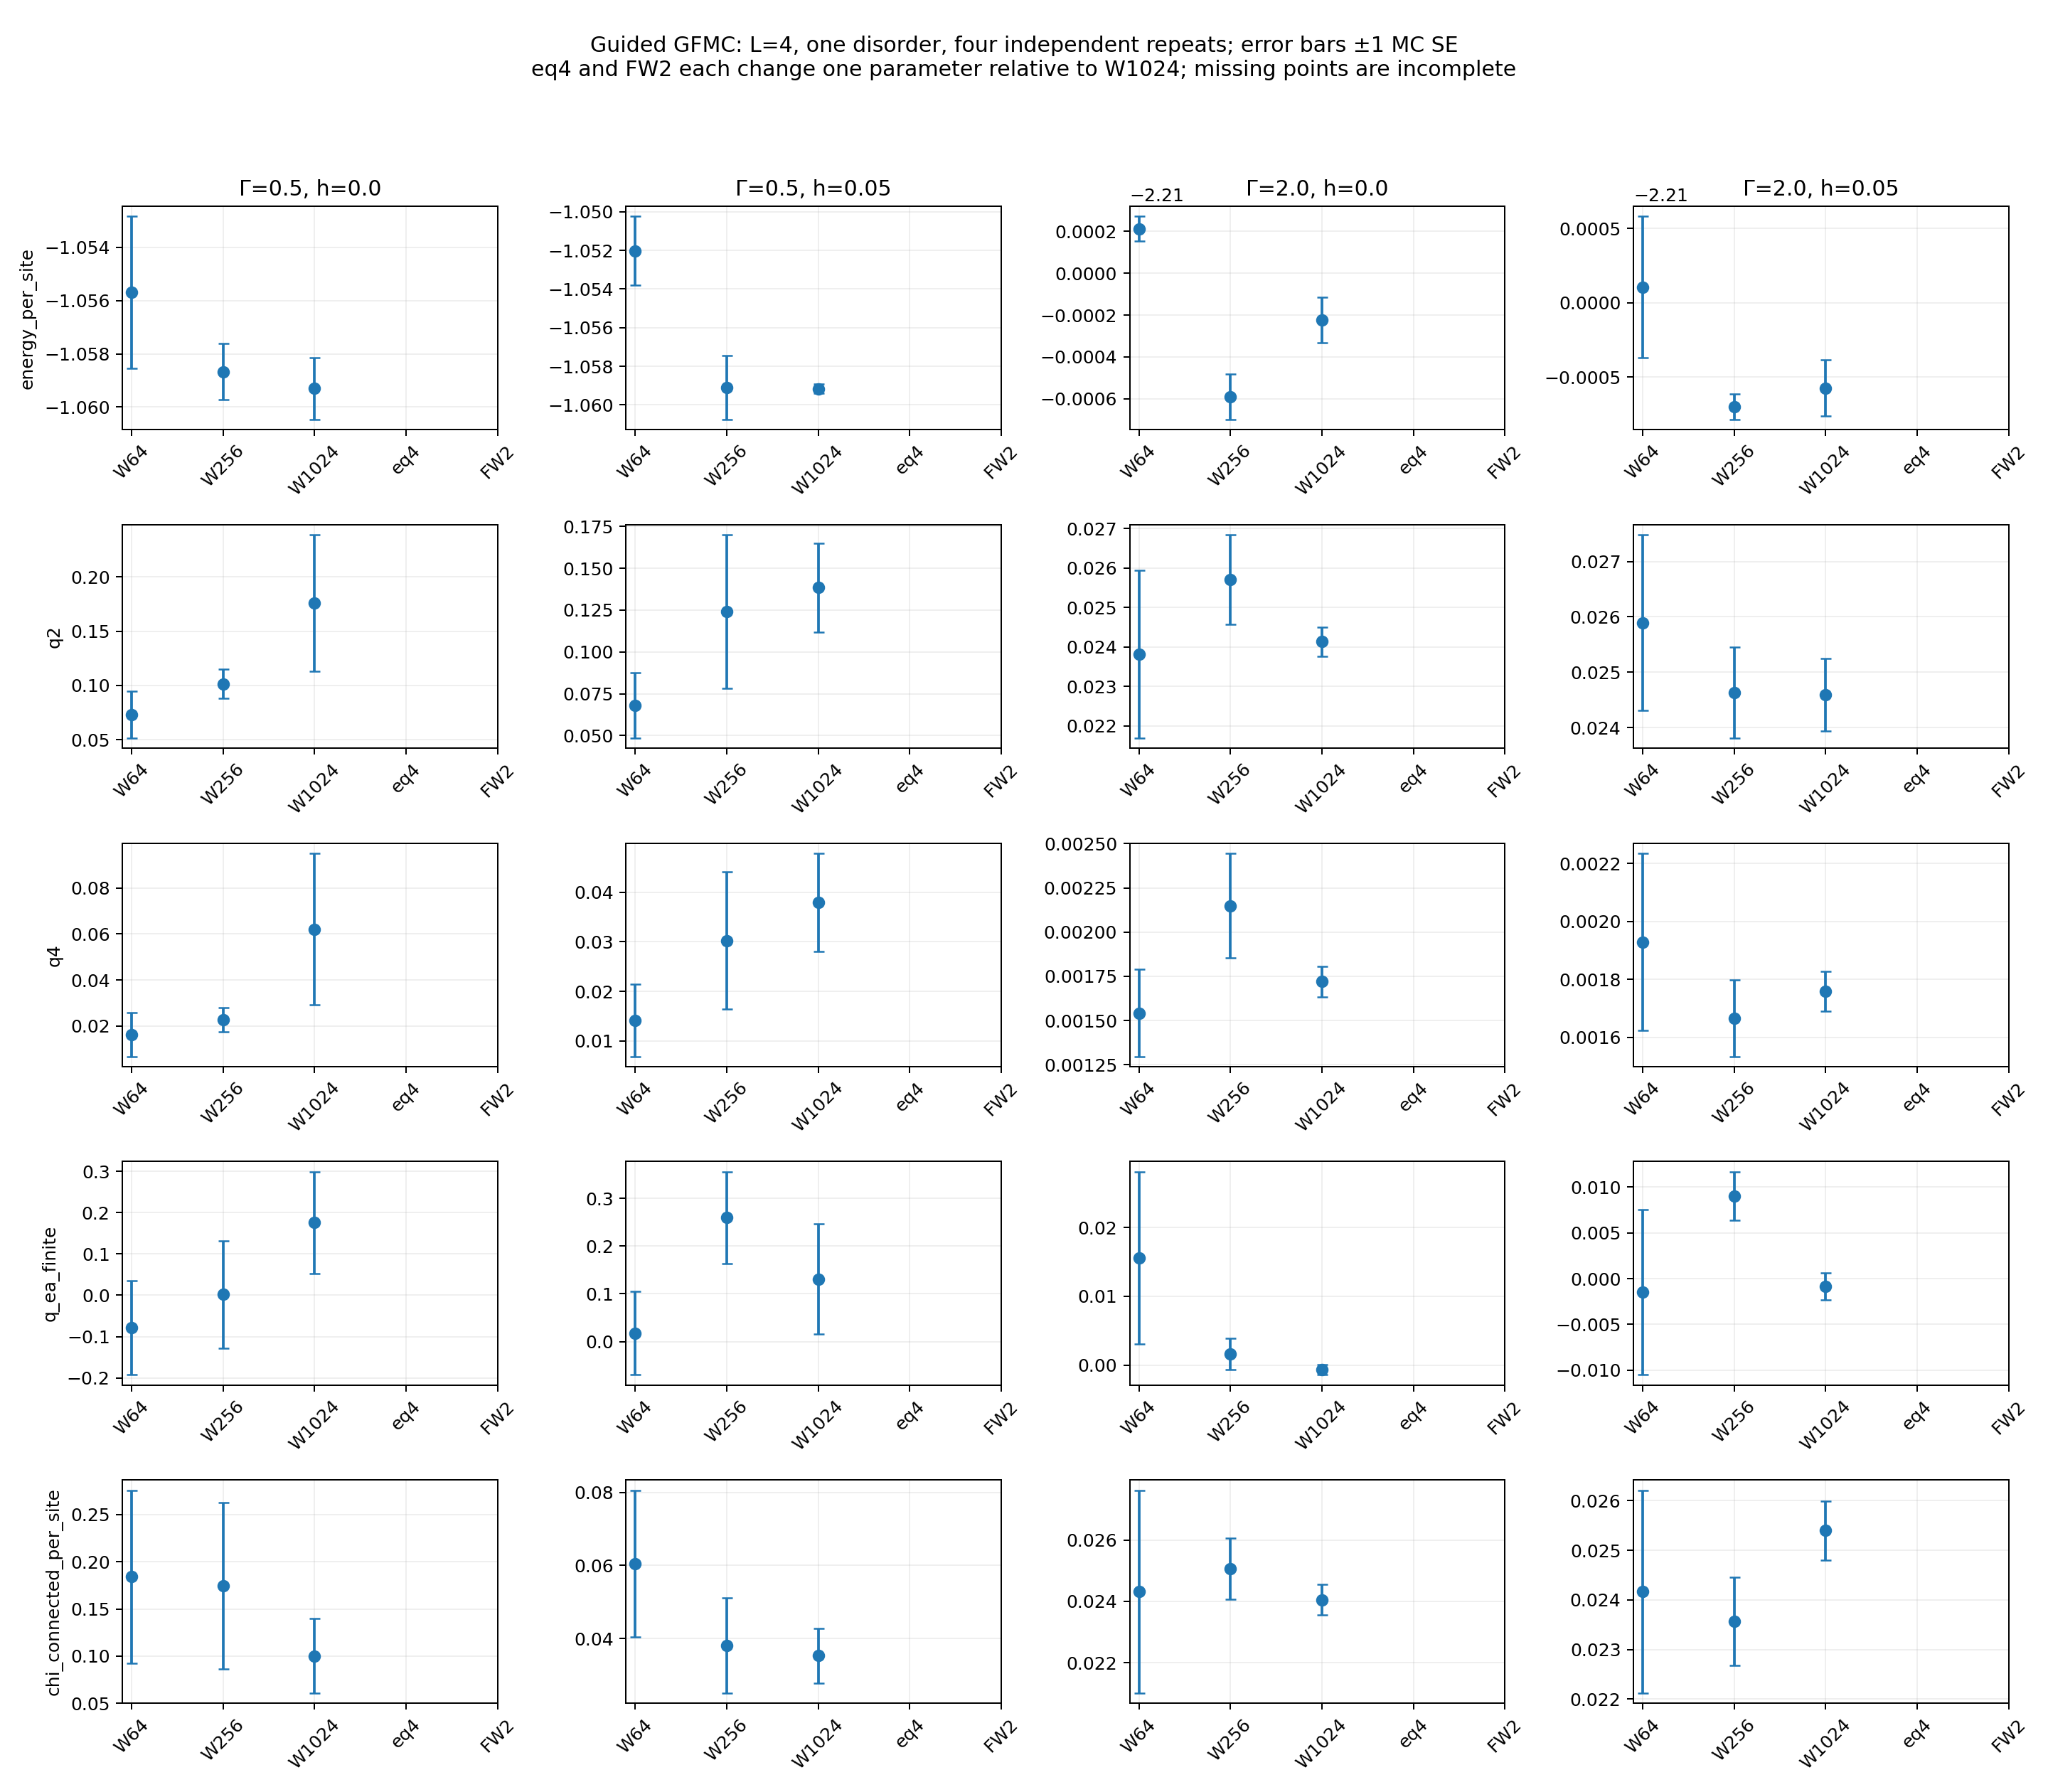

In [6]:
physical_review = ROOT / 'data/kagome/transformer_af_production_v1/PHYSICAL_CONVERGENCE.md'
if physical_review.exists():
    display(Markdown(physical_review.read_text()))
    physical_image = physical_review.parent / 'physical_convergence/guided_estimates.png'
    if physical_image.exists():
        display(Image(filename=str(physical_image)))

# Ancestry onset and exact overlap-distribution study

2026-10-27T09:32:06.737869+00:00

## Scientific question

Does deterioration of guided-GFMC ancestry as Gamma decreases coincide with changes in physical overlap distributions? Treat this as a hypothesis to test. Ancestry depends on the guide, W, projection time, branch cadence, number of cycles and disorder; it is not an order parameter.

## Exact definition and completed calculation

For two independent z-basis measurements of the same disorder ground state, q = sum_i s_i t_i / N and P_J(q) = sum_(s,t) |psi_J(s)|^2 |psi_J(t)|^2 1[q(s,t)=q]. This is an equal-time measurement distribution, not a decomposition into thermodynamic pure states.

Computed 784 distributions (exact plus available guide distributions) from existing 12-spin (L=2) references. No new diagonalization was needed. Each exact distribution is checked against stored q, q2 and q4, normalization and h=0 spin-flip symmetry. The guide distribution uses the frozen float64 guide before GFMC projection.

![Exact and guide overlap distributions](exact_guide_pq.png)

All 49 field contexts and eight disorders are exported. Discrete q bins have spacing 2/12. Disorder-average error bars are descriptive SE across disorders; exact diagonalization itself introduces no Monte Carlo error. At h=0 the finite-system P(q) is symmetric; nonzero h can shift and skew it. A 12-spin system has finite-size crossovers, not evidence of a thermodynamic singularity.

## Measured guide mismatch

The table gives the disorder mean of total variation distance, TV = (1/2) sum_q |P_exact(q)-P_guide(q)|. Zero means identical distributions; one means disjoint support. These compare the exact ground state with the unprojected guide, not with a converged GFMC estimate.

| Gamma | h=0 | h=0.05 | h=0.15 | h=0.30 |
|---:|---:|---:|---:|---:|
| 0.25 | 0.49513 | 0.53730 | 0.55328 | 0.56668 |
| 0.5 | 0.21061 | 0.27938 | 0.30861 | 0.33358 |
| 0.75 | 0.11697 | 0.16673 | 0.23454 | 0.28304 |
| 1.0 | 0.05139 | 0.05518 | 0.07719 | 0.14480 |
| 1.5 | 0.01350 | 0.01377 | 0.01378 | 0.01536 |
| 2.0 | 0.00537 | 0.00549 | 0.00543 | 0.00509 |
| 3.0 | 0.00049 | 0.00144 | 0.00153 | 0.00112 |

The guide agrees closely at Gamma >= 1.5, while the mismatch increases at lower Gamma. At h=0 the exact distribution moves toward both overlap extremes; nonzero h favors positive overlap. The guide underrepresents this concentration. This makes guide error a concrete possible contributor to ancestry loss. These 12-spin data cannot establish how much of the 48-spin ancestry loss is caused by guide error or identify a phase boundary.

## Ancestry onset protocol

1. Finish the active base and population/time tests. Report alarm fractions separately for each h and disorder, together with ESS/W, ancestor counts and largest lineage. The existing alarm is ESS < 8 or largest lineage > 0.5 in any cycle. Keep the cycle count fixed for onset comparisons.
2. At h=0 and h=0.05, scan downward from Gamma=2 through 1.75, 1.5, 1.25, 1 and 0.75. Retain Gamma=0.5 as the difficult endpoint. First use the same four fixed development disorders, four repeats, W256 and W1024, equilibration2, measurement1, forward1, cycles4, branch0.1 and float64 guide. New settings remain feasibility diagnostics. This scan is proposed, not dispatched; cost review follows the current escalations.
3. Summarize a diagnostic half-alarm crossing only when complete data bracket alarm fraction 0.5. Interpolate between adjacent tested Gamma values and show per-disorder curves; report nonmonotonicity or multiple crossings instead of forcing a threshold. Refine bracket midpoints only after measuring cost. Confidence assessment must respect disorder clustering; four disorders give limited precision.
4. Test whether the onset moves with W, forward time and guide choice. A moving onset identifies an algorithmic limitation; a stable onset is a candidate region for physical investigation, not proof of a transition.
5. Compare exact P(q), q2, q4 and connected correlations across the same fields. Compare the frozen guide with exact P(q) on each identical 12-spin disorder to diagnose guide mismatch. The current 12-spin and 48-spin disorder pools are different; cross-size comparisons are ensemble comparisons, not paired-sample tests.
6. Add descendant-weighted P(q) histogram tags to a separately validated projector snapshot. Existing scalar q-cycle averages cannot reconstruct P(q). Verify histogram normalization, moments and exact finite-forward targets at L=2 before using it at L=4. Complete convergence and finite-size checks before estimating a physical boundary.

## Refinement and finite-size extrapolation

Use the ancestry bracket to prioritize fields. At each fixed h, obtain qualified Binder and connected-correlation ratios on common field cuts for L=4,6,8,10, then L=5,7,9 with compatible geometry. The 12-spin exact result is a benchmark outside the primary scaling fit. Refine measured physical crossing brackets with common midpoint fields and fresh confirmation disorders. Retain absent or multiple crossings and their bootstrap frequency; do not silently condition the fit on successful crossing samples.

Resample each disorder whole across its field curve and moment set, and independently across sizes. Recompute every crossing jointly so shared-size covariance survives. Conditional fits use Gamma_cross = Gamma_c + A (sqrt(L1 L2))^(-lambda), initially checking fixed lambda=1,2,3. This effective-length ansatz is phenomenological; use compatible pair families, preferably fixed size ratios when available. Vary the minimum size and pair family and report statistical, interpolation, numerical and model sensitivity separately.

The tested utility `finite_size_crossings.py` locates crossings within measured brackets and fits joint bootstrap crossing samples with their covariance. At least three distinct effective lengths are required. Synthetic recovery tests validate the computation, not its physical applicability. Scaling collapse R_L = F((Gamma-Gamma_c)L^(1/nu)) is conditional on evidence for a continuous transition and suitable scaling of the chosen ratio. Sparse sizes may leave both Gamma_c and nu unresolved.

**Current inference status:** no qualified multi-size physical curves are available, so no measured physical crossing, thermodynamic transition estimate or critical exponent is reported. `next_stage_proposal.json` preserves the 448-combination guided onset design and common-size refinement requirements; it is not a dispatched queue. Cost and qualification evidence from the running escalation determine the next executable batch.

## Files

- `exact_and_guide_pq_by_disorder.csv`: every P_J(q) bin.
- `pq_disorder_summary.csv`: equal-weight disorder means and SE.
- `guide_exact_total_variation.csv`: per-context/disorder guide mismatch.
- `ancestry_by_disorder.csv`: field-resolved coverage and alarms, retaining incomplete groups.
- `next_stage_proposal.json`: proposed onset settings and gated finite-size refinement.
- `provenance.json`: input hashes and numerical/scientific limits.


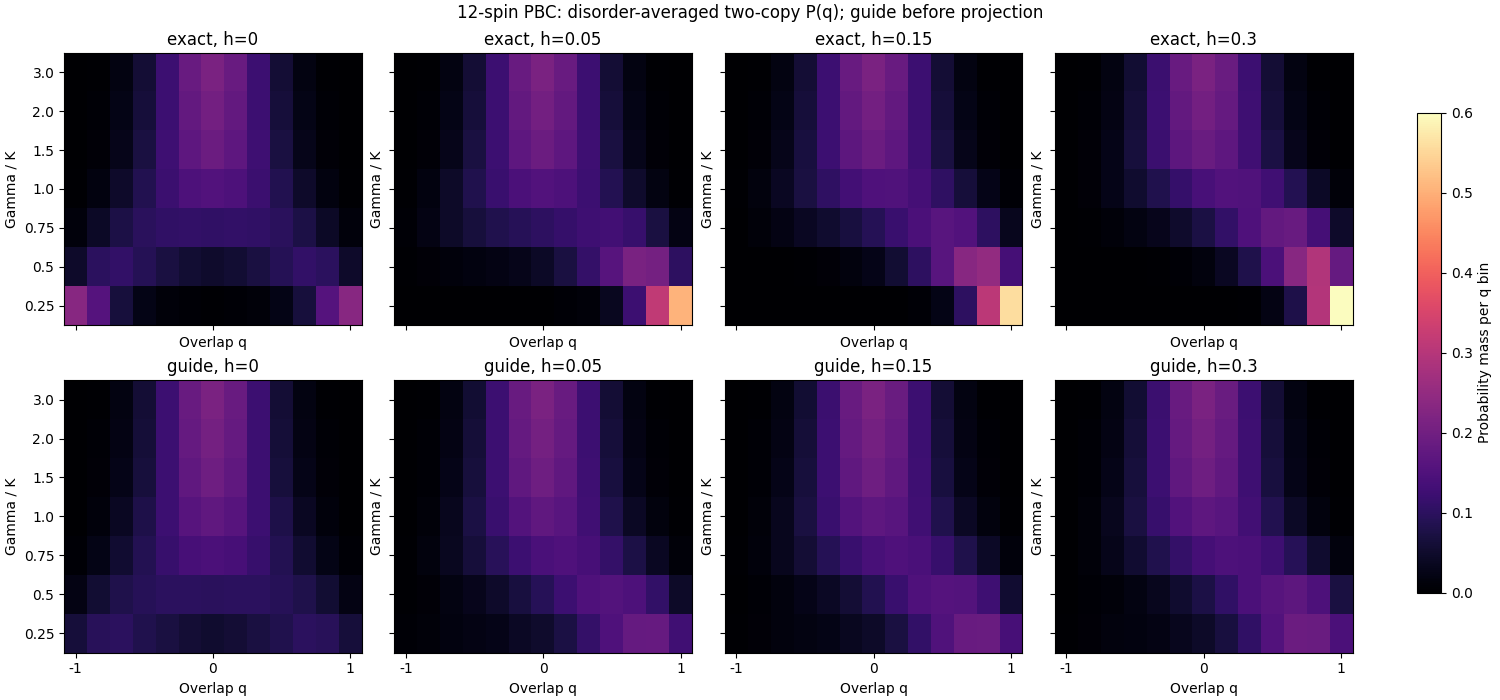

In [7]:
overlap_note = ROOT / 'data/kagome/transformer_af_production_v1/overlap_onset/RESEARCH_NOTE.md'
if overlap_note.exists():
    display(Markdown(overlap_note.read_text()))
    overlap_image = overlap_note.parent / 'exact_guide_pq.png'
    if overlap_image.exists():
        display(Image(filename=str(overlap_image)))